# Desarrollo del modelo — Geohelmintos en microscopía (rama de Machine Learning)

Proyecto final de **Fundamentos de Machine Learning** (prof. Yomin Estiven Jaramillo Munera), EAFIT 2026-2,
compartido con Redes Neuronales y Deep Learning. Equipo: **Samuel Llano Madrigal, Laura Andrea Castrillon y
Jerónimo Campuzano**. Alianza académica: Microbiología y Parasitología de la Universidad Pontificia Bolivariana
(UPB). Repositorio: https://github.com/JeronimoCampuzanoC/scrambled-eggs

Este es el entregable `model_development.ipynb`: el paso a paso del entrenamiento del modelo, con el EDA, sus
insights y la justificación de cada decisión. **Todos los números salen de las celdas de este notebook** (o de
los notebooks de apoyo que se citan), corridos sobre los datos reales.

**Resumen de resultados.**

| | Resultado |
|---|---|
| Modelo elegido | **SVM lineal** (`C = 0,003`) sobre el embedding DINOv2 estandarizado, elegido entre kNN, árbol, Random Forest, Gradient Boosting y SVM lineal y RBF con validación cruzada agrupada por foto |
| F1 macro, validación cruzada (`train`) | **0,990 ± 0,003** |
| F1 macro, `valid` | **0,990** (intervalo bootstrap 95 %: 0,980–0,998) |
| F1 macro, `test` (una sola vez) | **0,998** (0,993–1,000) con cajas dibujadas; **0,998** con las cajas del detector YOLO |
| Conteo por foto en `test` (409 fotos) | **96,6 %** exacto en las tres especies; 98,8 % exacto o con la diferencia marcada "consulte a un experto" |
| Tiempo por foto en CPU | ~90 ms (YOLO + DINOv2 + SVM), sin internet |
| Principal riesgo | Fotos desenfocadas o muy comprimidas (−4 a −25 puntos de F1); se detectan con el monitoreo de similitud (sección 11) |

| Requisito del enunciado | Sección |
|---|---|
| 3.1 Selección del problema | 1 |
| 3.2 Preprocesamiento | 2 |
| 3.3 EDA profundo e insights | 3 |
| 3.4 Paradigma: no supervisado y supervisado | 4 y 5 |
| 3.5 Metodología de entrenamiento y selección del modelo | 5 |
| 3.6 Generalización | 6 y 8 |
| 3.7 Métricas de desempeño | 7 |
| Explicabilidad con SHAP | 9 |
| 3.8 Despliegue e interfaz | 10 |
| 3.9 Estrategia de reajuste | 11 |

**Notebooks de apoyo** (en `notebooks/`, con sus salidas guardadas): `eda_dataset.ipynb` (EDA de las fotos),
`eda_embeddings.ipynb` (EDA de los embeddings) y `compare_detectors.ipynb` (elección del detector YOLO).

**Cómo correrlo.** Desde la raíz del repo, después de preparar los datos (ver el README:
`bash scripts/local/prepare_ml.sh`):

```bash
jupyter nbconvert --to notebook --execute --inplace notebooks/model_development.ipynb
```

Corre en una laptop en pocos minutos (CPU; DINOv2 usa MPS o CUDA si existen). No necesita internet.

## 1. El problema (3.1)

**Contexto.** Las geohelmintiasis (parásitos transmitidos por el suelo) afectan a cerca de 1.500 millones de
personas, sobre todo en comunidades con poco acceso a agua y saneamiento. En el **Chocó** son muy frecuentes:
en niños de comunidades indígenas, *Trichuris* y *Ascaris* aparecen en más del 70 % de los casos. El
diagnóstico es un **coprológico**: un microscopista recorre la lámina con la muestra de heces, identifica los
huevos por su **morfología** y, en el método Kato-Katz de la OMS, los **cuenta todos** para estimar la
intensidad de la infección (huevos por gramo, HPG).

**El cuello de botella.** Identificar y contar exige un microscopista entrenado que muchas brigadas no tienen,
es lento y se equivoca por fatiga. Y en la mayoría del Chocó **no hay internet**.

**Usuarios.** Microscopistas, bacteriólogos o personal de salud no especializado en brigadas de campo, con un
microscopio, un **celular** (fotos por el ocular) y una **laptop** sin conexión.

**Decisión que apoya.** Para cada foto: qué huevos hay (*Ascaris lumbricoides*, *Trichuris trichiura* o
uncinarias), cuántos, con qué seguridad, y cuándo **consultar a un experto**. Para cada lámina: el conteo por
especie y una **estimación** del HPG y de la intensidad OMS. **Es apoyo, nunca diagnóstico**: la confirmación
la hace un profesional.

**Datos.** *Chula-ParasiteEgg-11* (Universidad Chulalongkorn, reto ICIP 2022; licencia CC BY 4.0), copia
completa en Roboflow (`parasites-onxa6/parasites-trgfz` v1). De sus 11 especies usamos las 3 geohelmintos:
2731 fotos con 2749 huevos, unos 900 por especie, cada uno con su caja dibujada a mano. Sin datos de pacientes.

**Arquitectura en dos etapas.** Separar *dónde* está el huevo de *qué* huevo es:

```
foto ──► YOLO11n (detector de "huevo")  ──► recorte de cada huevo ──► DINOv2 congelado (embedding de 768 números)
                                                                         │
                                       rama ML (este notebook): modelo clásico ──► especie + confianza
                                                                         │
                                      conteo por lámina ──► HPG = total × 24 ──► app offline
```

- **Detector** (entrenado aparte, ver `compare_detectors.ipynb`): YOLO11n de una sola clase, con aumentos de
  color y de calidad de celular. En `valid` encuentra 412 de 413 huevos (recall 0,998, precisión 0,990 con
  umbral 0,25); en 6 fotos externas de celular encontró 7 de 8 huevos sin falsas alarmas, contra 4 de 8 del
  modelo sin aumentos. Por eso se usa el modelo con aumentos.
- **Clasificador (este notebook):** recibe el recorte del huevo y decide la especie. Con ~1900 recortes de
  entrenamiento no se puede aprender una red desde cero, pero sí representar cada recorte con un modelo
  preentrenado (**DINOv2**, Oquab et al. 2023, autosupervisado en 142 M imágenes) y aprender encima con
  **modelos clásicos** del curso. DINOv2 queda **congelado**: no se ajusta nada de la red; todo el aprendizaje
  lo hacen los modelos de sklearn. (La rama de Deep Learning, en el otro curso, sí ajusta redes completas.)

In [1]:
import os

# torch (pip) and scikit-learn (conda) ship two OpenMP runtimes; once scikit-learn's OpenMP code runs,
# loading DINOv2 in the same process hangs. One OpenMP thread avoids it (sklearn still parallelizes with
# processes, and DINOv2 runs on MPS/CUDA when available). Must be set before importing numpy/sklearn/torch.
os.environ["OMP_NUM_THREADS"] = "1"

import json
import subprocess
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image, ImageEnhance, ImageFilter
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.base import clone
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, normalized_mutual_info_score, silhouette_score)
from sklearn.model_selection import (GridSearchCV, StratifiedGroupKFold, StratifiedKFold, cross_val_score,
                                     learning_curve)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

/opt/miniconda3/envs/machine-learning-test/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
EMBEDDINGS_NPZ = ROOT / "artifacts" / "embeddings" / "dinov2_vitb14_224.npz"
CROPS_CSV = ROOT / "data" / "crops" / "crops.csv"
DETECTED = {split: (ROOT / "artifacts" / "embeddings_detected" / split / "dinov2_vitb14_224.npz",
                    ROOT / "artifacts" / "detected" / split / "crops.csv") for split in ("valid", "test")}
BUNDLE_PATH = ROOT / "artifacts" / "ml" / "egg_classifier.joblib"
assert all(p.is_file() for p in (EMBEDDINGS_NPZ, CROPS_CSV, *[p for pair in DETECTED.values() for p in pair])), \
    "prepare the data first: bash scripts/local/prepare_ml.sh"

CLASSES = ["ascaris", "hookworm", "trichuris"]
SEED = 42
N_FOLDS = 5
DET_CONF = 0.25   # detection threshold decided in compare_detectors.ipynb

# Same palette as the other notebooks
COLORS = {"ascaris": "#2a78d6", "hookworm": "#eb6834", "trichuris": "#1baf7a"}
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1", "#fcfcfb"
ALERT = "#b3261e"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": INK, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
pd.set_option("display.precision", 3)
print("scikit-learn", sklearn.__version__, "| shap", shap.__version__)

scikit-learn 1.9.0 | shap 0.52.0


In [3]:
def load_embeddings(npz_path, crops_csv_path):
    """Crop metadata (one row per crop) and the two embedding matrices, in the same order."""
    data = np.load(npz_path, allow_pickle=True)  # our own file: it stores the strings as objects
    crops = pd.read_csv(crops_csv_path)
    assert len(crops) == len(data["cls"]), "npz and crops.csv have a different number of crops"
    assert (crops.crop_path.to_numpy() == data["crop_paths"]).all(), "npz and crops.csv are not aligned"
    return crops, data["cls"], data["patch_mean"]


def to_unit(vectors):
    """Scale every vector to length 1, so that a dot product is the cosine similarity."""
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


def show_crop(ax, crop_path, title):
    ax.imshow(Image.open(ROOT / crop_path))
    ax.set_title(title, fontsize=8, loc="center", fontweight="normal")
    ax.axis("off")


def draw_heatmap(ax, values, title, fmt="{:.2f}", vmin=None, vmax=None):
    """A table as a heatmap with its numbers written in the cells (darker = larger)."""
    numbers = values.to_numpy(dtype=float)
    vmin = numbers.min() if vmin is None else vmin
    vmax = numbers.max() if vmax is None else vmax
    ax.imshow(numbers, cmap=BLUES, vmin=vmin, vmax=vmax, aspect="auto")
    for (row, col), number in np.ndenumerate(numbers):
        darkness = (number - vmin) / (vmax - vmin) if vmax > vmin else 0
        ax.text(col, row, fmt.format(number), ha="center", va="center", fontsize=9,
                color=SURFACE if darkness > 0.6 else INK)
    ax.set_xticks(range(values.shape[1]), values.columns, rotation=30, ha="right")
    ax.set_yticks(range(values.shape[0]), values.index)
    ax.set_title(title)
    ax.grid(False)


def draw_confusion(ax, y_true, y_pred, title):
    matrix = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=CLASSES), index=CLASSES, columns=CLASSES)
    draw_heatmap(ax, matrix, title, fmt="{:.0f}")
    ax.set(xlabel="predicha", ylabel="real")


all_crops, all_cls, all_patch_mean = load_embeddings(EMBEDDINGS_NPZ, CROPS_CSV)
print(f"{len(all_crops)} crops loaded from {EMBEDDINGS_NPZ.relative_to(ROOT)}")

2749 crops loaded from artifacts/embeddings/dinov2_vitb14_224.npz


## 2. Datos y preprocesamiento (3.2)

### 2.1 De la foto al vector

Cada paso tiene una razón. Los scripts están en `src/` y se corren antes de este notebook.

| Paso | Script | Qué hace | Por qué |
|---|---|---|---|
| Filtrado de clases | `src/data/filter_classes.py` | De 11 especies deja las 3 geohelmintos (ids 0–2) | Son las que Kato-Katz cuantifica y las del problema |
| **Partición** | `src/data/filter_classes.py` | 70/15/15 **por foto original**, estratificada por especie, seed 42 | Los huevos de una misma foto nunca quedan en dos particiones (sin fuga). Detector, rama ML y rama DL usan la misma partición |
| Recorte | `src/data/crop_eggs.py` | Un recorte por huevo con la caja + 15 % de margen | El clasificador ve el huevo ampliado y un poco de contexto (cáscara completa) |
| Relleno a cuadrado | `src/embeddings/extract_embeddings.py` | Rellena con el color medio del recorte en vez de estirar | La **forma** (redonda o alargada, con tapones) es lo que distingue a las especies: estirar la destruye |
| 224 × 224 + normalización ImageNet | ídem | Tamaño y escala de color que espera DINOv2 | DINOv2 se entrenó así |
| Embedding DINOv2 ViT-B/14 | ídem | Token CLS de 768 números por recorte | Representación genérica y robusta; los modelos clásicos necesitan vectores de tamaño fijo |
| **Estandarización** | `StandardScaler` dentro del `Pipeline` | Media 0 y varianza 1 por dimensión | kNN, SVM y PCA dependen de las distancias: sin escalar, unas pocas dimensiones dominarían |
| **PCA** | `PCA` dentro del `Pipeline` | Reduce las 768 dimensiones (el número es un hiperparámetro) | 768 dimensiones con ~1900 muestras: quitar ruido y acelerar árboles y kNN |

**Escalado y PCA se ajustan dentro de cada pliegue** de la validación cruzada (por eso van en el `Pipeline`):
si se ajustaran con todos los datos, la información de los pliegues de validación se filtraría al entrenamiento.

### 2.2 Revisiones: faltantes, atípicos, codificación y fuga

- **Valores faltantes:** los embeddings no deberían tener ninguno (se verifica abajo). Las etiquetas vienen de
  las cajas: un recorte sin especie no existe por construcción. Hay **una** foto sin anotación
  (`Hookworm-egg_0339`, ver `eda_dataset.ipynb`): queda fuera, sin corregirla a mano.
- **Atípicos:** en un embedding no se recorta por rango como en una tabla. Se buscan recortes "raros" con
  DBSCAN y con los vecinos más cercanos (secciones 3 y 4) y se **documentan para revisión de un experto**, no
  se borran: borrarlos haría el problema artificialmente fácil.
- **Codificación:** la única variable categórica es la etiqueta (3 especies); sklearn la maneja como texto.
- **Balance:** ~900 huevos por especie, así que no hace falta re-muestrear ni pesar clases.

In [4]:
print("NaN values:", int(np.isnan(all_cls).sum()), "| infinite values:", int(np.isinf(all_cls).sum()))
print("Original photos spread over more than one split:",
      int((all_crops.groupby("group").split.nunique() > 1).sum()))
print("Photos with more than one egg:", int((all_crops.group.value_counts() > 1).sum()))

# From here on, `test` stays frozen: only section 8 touches it, once, with the final model.
is_dev = all_crops.split.isin(["train", "valid"]).to_numpy()
crops = all_crops[is_dev].reset_index(drop=True)
X_cls, X_patch = all_cls[is_dev], all_patch_mean[is_dev]
y = crops.label.to_numpy()
groups = crops.group.to_numpy()
is_train = (crops.split == "train").to_numpy()
is_valid = ~is_train
X_train, y_train, g_train = X_cls[is_train], y[is_train], groups[is_train]
X_valid, y_valid, g_valid = X_cls[is_valid], y[is_valid], groups[is_valid]
print(f"Development crops: {is_train.sum()} train + {is_valid.sum()} valid (test kept aside)")

NaN values: 0 | infinite values: 0
Original photos spread over more than one split: 0
Photos with more than one egg: 18
Development crops: 1924 train + 413 valid (test kept aside)


## 3. Análisis exploratorio (3.3)

El EDA completo de las fotos y de los embeddings está en `eda_dataset.ipynb` y `eda_embeddings.ipynb`. Aquí se
repiten las vistas que justifican las decisiones del modelo y, al final, una tabla de **insight → decisión**.
Todo usa solo `train` y `valid`.

### 3.1 Inventario y balance

In [5]:
inventory = pd.crosstab(all_crops.split, all_crops.label).reindex(["train", "valid", "test"])
inventory["total"] = inventory.sum(axis=1)
inventory.loc["total"] = inventory.sum()
display(inventory.rename_axis(index="crops", columns=None))
print("Share of each species in train:", (pd.Series(y_train).value_counts(normalize=True).round(3)).to_dict())

,ascaris,hookworm,trichuris,total
crops,,,,
train,636,650,638,1924
valid,136,140,137,413
test,138,138,136,412
total,910,928,911,2749


Share of each species in train: {'hookworm': 0.338, 'trichuris': 0.332, 'ascaris': 0.331}


Las tres especies tienen casi el mismo número de huevos y las proporciones se repiten en las tres
particiones. **Decisión:** no hace falta re-muestreo; la métrica principal es **F1 macro**, que pesa igual a
las tres especies.

### 3.2 Cómo se ven los huevos

Seis recortes al azar de cada especie (`train`, seed del proyecto). Las diferencias son de **forma y
cáscara**: *Ascaris* es ovalado-redondo con cáscara gruesa y mamelonada; la uncinaria tiene cáscara delgada y
transparente; *Trichuris* tiene forma de barril con dos tapones polares.

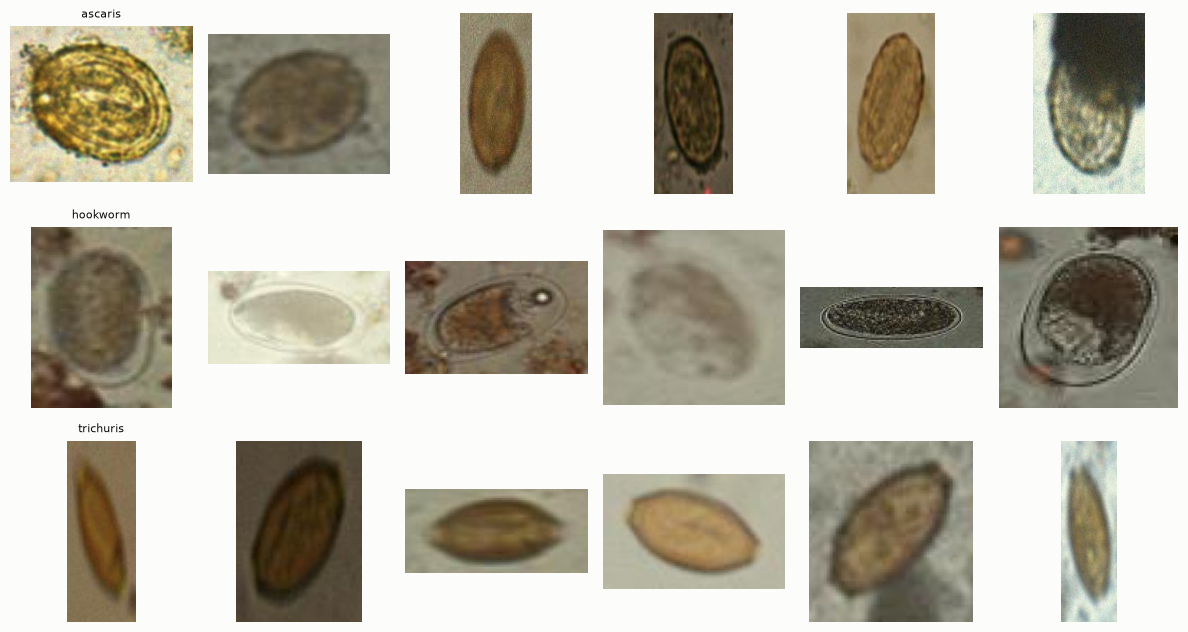

In [6]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 6, figsize=(12, 6.4))
for row, name in enumerate(CLASSES):
    for col, index in enumerate(rng.choice(np.flatnonzero(is_train & (y == name)), 6, replace=False)):
        show_crop(axes[row, col], crops.crop_path[index], name if col == 0 else "")
plt.tight_layout()
plt.show()

### 3.3 Tamaño y forma de la caja

El tamaño del huevo en la foto depende del aumento del microscopio y del recorte de la foto, así que no es una
medida física. Se mide el lado mayor de la caja (px en la foto de 640 × 640) y la relación ancho/alto.

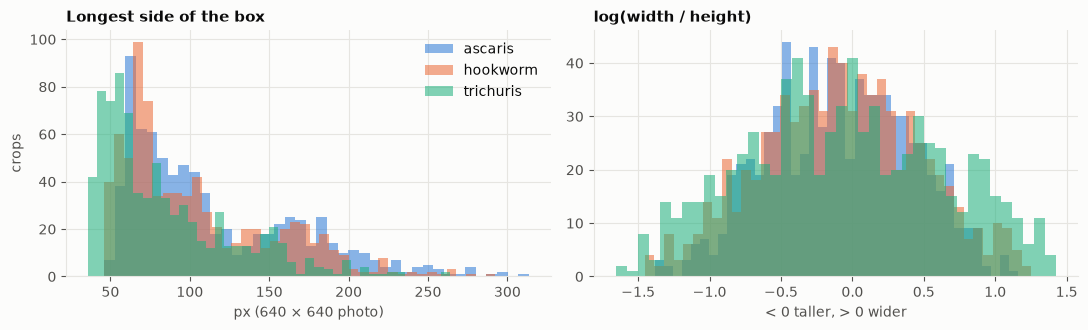

,mean,std,25%,50%,75%,std / mean
ascaris,114.87,53.13,71.88,98.0,153.50,0.46
hookworm,104.91,48.00,68.00,89.5,136.38,0.46
trichuris,84.72,42.04,53.25,70.5,106.00,0.50


In [7]:
box_size = crops[["box_w", "box_h"]].max(axis=1)
log_aspect = np.log(crops.box_w / crops.box_h)
fig, (ax_size, ax_aspect) = plt.subplots(1, 2, figsize=(11, 3.4))
for name in CLASSES:
    mask = y == name
    ax_size.hist(box_size[mask], bins=40, alpha=0.55, color=COLORS[name], label=name)
    ax_aspect.hist(log_aspect[mask], bins=40, alpha=0.55, color=COLORS[name], label=name)
ax_size.set(title="Longest side of the box", xlabel="px (640 × 640 photo)", ylabel="crops")
ax_aspect.set(title="log(width / height)", xlabel="< 0 taller, > 0 wider")
ax_size.legend()
plt.tight_layout()
plt.show()
size_by_class = box_size.groupby(y).describe()[["mean", "std", "25%", "50%", "75%"]]
size_by_class["std / mean"] = size_by_class["std"] / size_by_class["mean"]
display(size_by_class.round(2))

**Insight.** Los tamaños de las tres especies se solapan casi por completo (la dispersión dentro de cada
especie es de alrededor de la mitad de la media), y la relación ancho/alto se reparte a ambos lados de 0
porque los huevos aparecen en cualquier orientación. El promedio de log(ancho/alto) queda en ≈ −0,07: Roboflow
**estiró** las fotos a 640 × 640 y quedaron ~7 % más angostas (ver `eda_dataset.ipynb`). **Decisiones:** el
tamaño en píxeles **no** se usa como variable; el recorte se rellena a cuadrado para no deformar más; la
deformación se reporta como limitación.

### 3.4 Brillo y color: ¿hay atajos?

Un **atajo** es una pista que no es del huevo (la luz, la cámara, la tinción de cada fuente) pero que delata
la especie. Si existe, el modelo acierta en el laboratorio y falla en el Chocó. Se mide sobre cada recorte el
brillo medio, el contraste (desviación del gris) y la "calidez" (rojo − azul; positivo = amarillento).

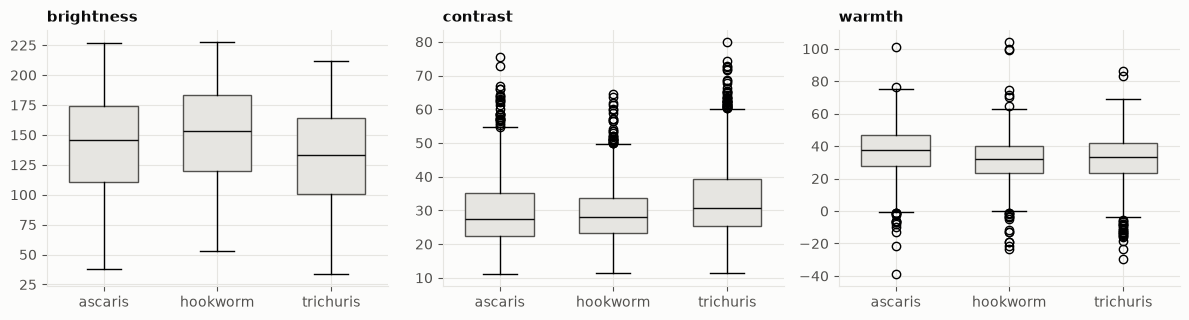

,brightness,contrast,warmth
ascaris,146.0,27.6,37.9
hookworm,152.9,28.0,32.1
trichuris,133.6,30.7,33.1


In [8]:
def crop_stats(crop_path):
    """Brightness, contrast and warmth measured on the crop itself."""
    rgb = np.asarray(Image.open(ROOT / crop_path).convert("RGB"), dtype=np.float32)
    gray = rgb.mean(axis=2)
    return {"brightness": gray.mean(), "contrast": gray.std(),
            "warmth": rgb[..., 0].mean() - rgb[..., 2].mean()}


pixel_stats = pd.DataFrame([crop_stats(path) for path in crops.crop_path])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, measure in zip(axes, pixel_stats.columns):
    ax.boxplot([pixel_stats.loc[y == name, measure] for name in CLASSES], tick_labels=CLASSES,
               patch_artist=True, widths=0.6, medianprops={"color": INK},
               boxprops={"facecolor": GRID, "edgecolor": INK2})
    ax.set_title(measure)
plt.tight_layout()
plt.show()
display(pixel_stats.groupby(y).median().round(1))

**Insight.** Las diferencias son moderadas pero existen: los recortes de uncinaria son los más claros (la
cáscara delgada y transparente deja ver el fondo), los de *Trichuris* los más oscuros y con más contraste (cáscara
café gruesa) y los de *Ascaris* los más cálidos. Una parte es morfología real y otra pueden ser condiciones de
captura de Chula, y desde los datos no se pueden separar del todo. **Decisiones:** (1) en la sección 6.4 se entrena un
**modelo de control** que solo ve estas medidas y el tamaño: si acierta mucho, hay un atajo; (2) la robustez
se prueba alterando brillo, contraste y color (sección 6.5); (3) el detector se entrenó con aumentos de color
para no aprender la luz de Chula.

### 3.5 El espacio de los embeddings

¿Cuántas de las 768 dimensiones importan y se ven las especies separadas? El PCA se ajusta solo con `train`.

Components needed: {'50%': 11, '80%': 68, '90%': 151, '95%': 253}


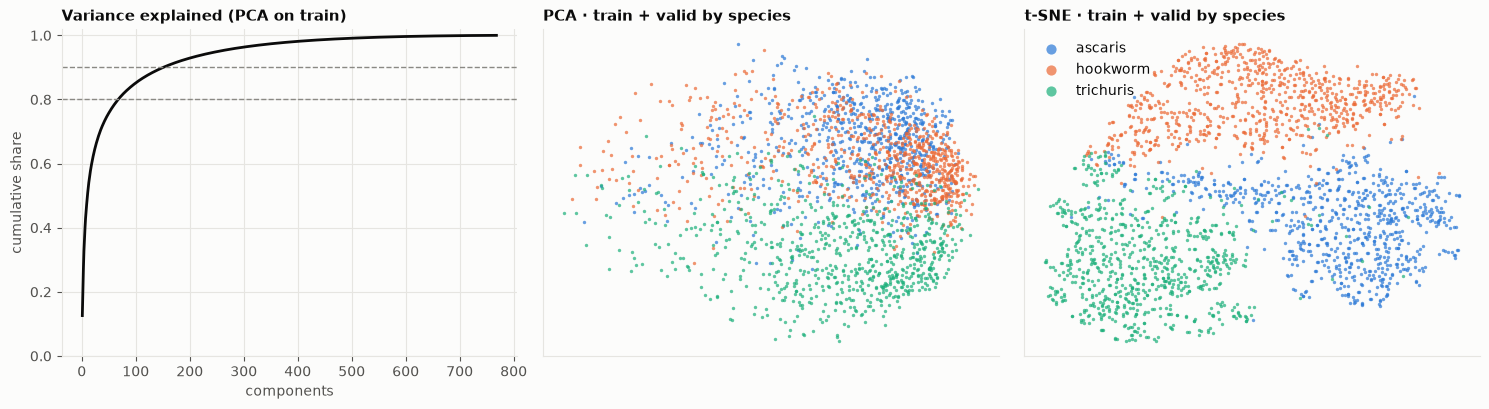

In [9]:
scaler_eda = StandardScaler().fit(X_train)
pca_eda = PCA(random_state=SEED).fit(scaler_eda.transform(X_train))
components_dev = pca_eda.transform(scaler_eda.transform(X_cls))
cumulative = np.cumsum(pca_eda.explained_variance_ratio_)
needed = {f"{share:.0%}": int(np.searchsorted(cumulative, share) + 1) for share in (0.5, 0.8, 0.9, 0.95)}
print("Components needed:", needed)

tsne_coordinates = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(
    components_dev[:, :50])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(np.arange(1, len(cumulative) + 1), cumulative, color=INK, linewidth=2)
for share in (0.8, 0.9):
    axes[0].axhline(share, color=MUTED, linestyle="--", linewidth=1)
axes[0].set(title="Variance explained (PCA on train)", xlabel="components", ylabel="cumulative share",
            ylim=(0, 1.02))
for ax, coordinates, method in ((axes[1], components_dev[:, :2], "PCA"), (axes[2], tsne_coordinates, "t-SNE")):
    for name in CLASSES:
        mask = y == name
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=6, alpha=0.7, color=COLORS[name],
                   linewidths=0, label=name)
    ax.set(title=f"{method} · train + valid by species", xticks=[], yticks=[])
    ax.grid(False)
axes[2].legend(markerscale=3)
plt.tight_layout()
plt.show()

**Insight.** La varianza está muy repartida: hacen falta 68 componentes para el 80 % y 151 para el 90 %, y los
dos primeros explican apenas una quinta parte. En el plano de los dos primeros componentes las especies se
mezclan, pero t-SNE (que conserva los vecinos) muestra tres grupos bastante limpios con una zona de contacto.
**Decisiones:** el número de componentes del PCA se elige por validación cruzada (no hay un "codo" claro), y se
esperan buenos resultados de modelos basados en vecindad o en fronteras en alta dimensión (kNN, SVM).

### 3.6 Vecinos más cercanos y casi-duplicados entre particiones

Si un recorte de `valid` fuera casi idéntico a uno de `train`, las métricas saldrían infladas. Para cada recorte
de `valid` se busca su recorte más parecido en `train` (similitud coseno; 1 = idénticos en dirección). También
se mide la **pureza de vecinos**: de los 10 recortes más parecidos a cada recorte (sin contar los de su misma
foto), qué parte es de su misma especie.

Similarity of each valid crop to its closest train crop: {'min': 0.641, '25%': 0.886, '50%': 0.919, '75%': 0.939, 'max': 0.978}
Neighbor purity (10 neighbors): {'ascaris': 0.923, 'hookworm': 0.944, 'trichuris': 0.917}


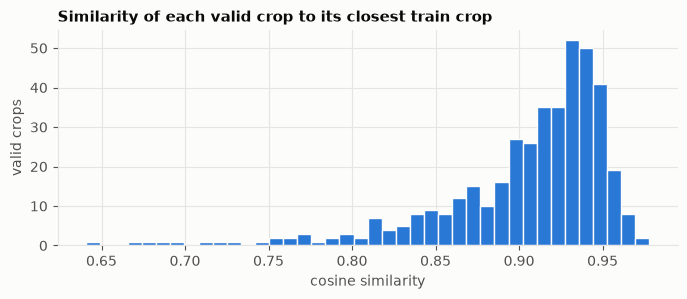

In [10]:
unit_dev = to_unit(X_cls)
similarity_valid_train = unit_dev[is_valid] @ unit_dev[is_train].T
closest_valid_train = similarity_valid_train.max(axis=1)
print("Similarity of each valid crop to its closest train crop:",
      pd.Series(closest_valid_train).describe()[["min", "25%", "50%", "75%", "max"]].round(3).to_dict())

similarity_all = unit_dev @ unit_dev.T
group_codes = pd.factorize(groups)[0]
similarity_all[group_codes[:, None] == group_codes[None, :]] = -np.inf
neighbors = np.argpartition(-similarity_all, 10, axis=1)[:, :10]
purity = pd.Series((y[neighbors] == y[:, None]).mean(axis=1)).groupby(y).mean()
print("Neighbor purity (10 neighbors):", purity.round(3).to_dict())

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(closest_valid_train, bins=40, color=COLORS["ascaris"], edgecolor=SURFACE)
ax.set(title="Similarity of each valid crop to its closest train crop", xlabel="cosine similarity",
       ylabel="valid crops")
plt.show()

**Insight.** Ningún recorte de `valid` es una copia de uno de `train`: la similitud máxima queda por debajo de
1 y la mayoría está alrededor de 0,9, el mismo rango de dos huevos distintos de la misma especie (en
`eda_embeddings.ipynb` se revisan a ojo las parejas más parecidas: son huevos distintos). Más del 90 % de los
vecinos de cada recorte son de su misma especie. **Decisiones:** la partición por foto es suficiente contra la
fuga; kNN es un candidato serio; y la "similitud con el recorte más parecido de entrenamiento" sirve como
señal de **fuera de distribución** (secciones 7.4 y 11).

### 3.7 Insights → decisiones

| Insight del EDA | Decisión |
|---|---|
| ~900 huevos por especie, mismas proporciones en las tres particiones | Sin re-muestreo; métrica principal **F1 macro** |
| 18 fotos con 2 huevos; los huevos de una foto se parecen | Partición y validación cruzada **agrupadas por foto** (`StratifiedGroupKFold`) |
| Sin duplicados entre particiones (fotos y embeddings) | La evaluación en `valid`/`test` es honesta |
| El tamaño en píxeles se solapa entre especies y depende del aumento | No se usa como variable; recorte rellenado a cuadrado |
| Fotos estiradas ~7 % por Roboflow | Se reporta como limitación |
| Contraste y color difieren un poco por especie | Modelo de control de atajos (6.4) y prueba de robustez (6.5) |
| Varianza repartida en muchas dimensiones | Número de componentes del PCA como hiperparámetro |
| Especies separadas por vecindad (t-SNE, pureza > 0,9) | kNN y SVM como candidatos; similitud como señal de rechazo |
| Puntero rojo del ocular más frecuente en fotos de *Ascaris* (`eda_dataset.ipynb`) | El detector se entrenó con punteros sintéticos; el recorte deja fuera casi todo el puntero |

## 4. Aprendizaje no supervisado (3.4)

Antes de usar las etiquetas: ¿las especies se separan solas? ¿Aparecen subgrupos o recortes raros? Se usan
los recortes de `train`, normalizados a longitud 1 (similitud coseno, la natural para DINOv2) y reducidos con
PCA a 50 componentes. El acuerdo con las especies se mide con **ARI** (índice de Rand ajustado: 0 = azar,
1 = idéntico) y **NMI** (información mutua normalizada); la cohesión de los grupos, con la **silueta**.

,inertia,silhouette,ARI,NMI
k,,,,
2,381.623,0.196,0.009,0.011
3,354.004,0.096,0.318,0.343
4,332.147,0.098,0.596,0.565
5,316.505,0.102,0.545,0.526
6,305.218,0.093,0.450,0.467
7,294.956,0.093,0.432,0.488
8,287.612,0.081,0.332,0.422


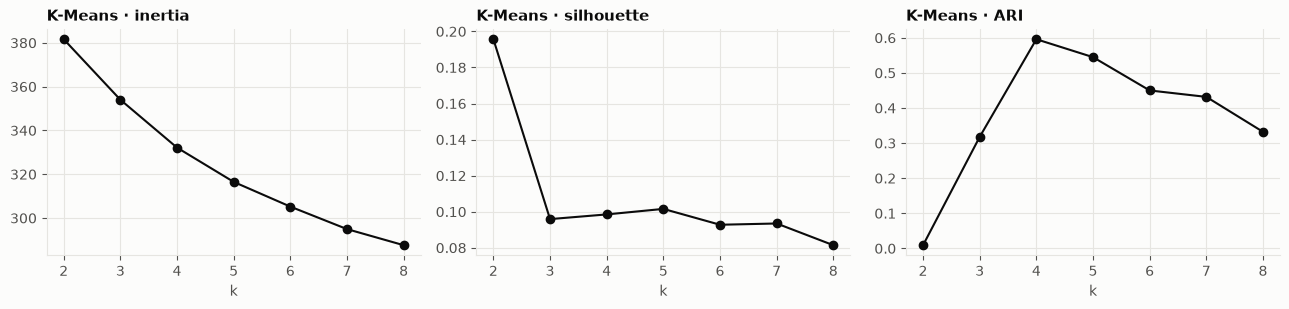

In [11]:
unsupervised_pca = PCA(n_components=50, random_state=SEED).fit(normalize(X_train))
Z_train = unsupervised_pca.transform(normalize(X_train))

rows = []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_train)
    rows.append({"k": k, "inertia": kmeans.inertia_, "silhouette": silhouette_score(Z_train, kmeans.labels_),
                 "ARI": adjusted_rand_score(y_train, kmeans.labels_),
                 "NMI": normalized_mutual_info_score(y_train, kmeans.labels_)})
kmeans_table = pd.DataFrame(rows).set_index("k")
display(kmeans_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, column in zip(axes, ["inertia", "silhouette", "ARI"]):
    ax.plot(kmeans_table.index, kmeans_table[column], marker="o", color=INK)
    ax.set(title=f"K-Means · {column}", xlabel="k")
plt.tight_layout()
plt.show()

### 4.1 K-Means: tres especies… y un cuarto grupo

La silueta es baja para todo `k` (los grupos no son esferas bien separadas), pero el acuerdo con las especies
sube mucho al pasar de `k = 3` a `k = 4`. La tabla de contingencia de `k = 3` y `k = 4` muestra por qué.

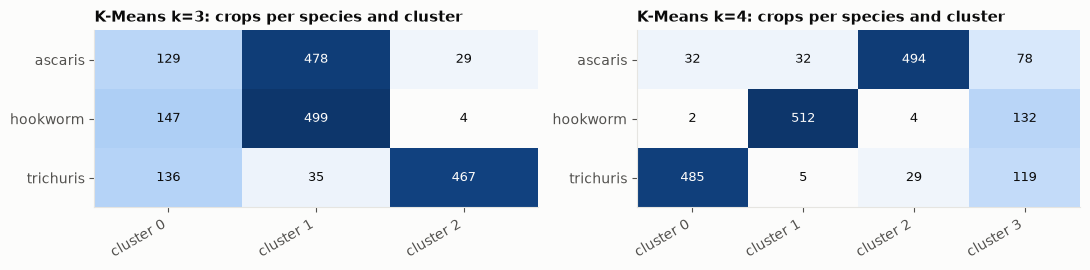

,mixed cluster,rest of train
brightness,124.0,147.5
contrast,25.4,29.7
warmth,38.2,33.3
box_size,95.5,84.5


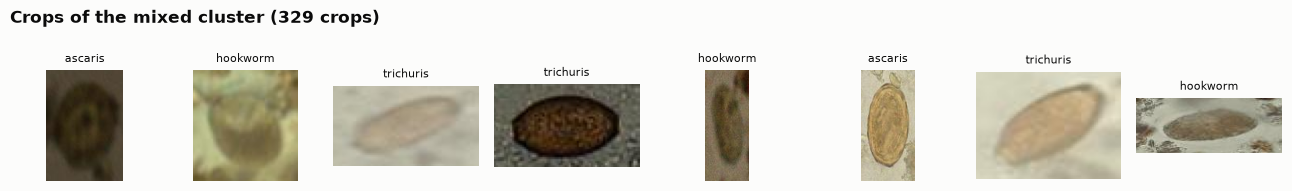

In [12]:
kmeans_3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Z_train)
kmeans_4 = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(Z_train)
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for ax, model in zip(axes, (kmeans_3, kmeans_4)):
    table = pd.crosstab(pd.Series(y_train, name="species"), pd.Series(model.labels_, name="cluster"))
    table.columns = [f"cluster {c}" for c in table.columns]
    draw_heatmap(ax, table, f"K-Means k={model.n_clusters}: crops per species and cluster", fmt="{:.0f}")
plt.tight_layout()
plt.show()

# The cluster of k=4 that mixes the three species: what do its crops have in common?
train_stats = pixel_stats[is_train].reset_index(drop=True).assign(box_size=box_size[is_train].to_numpy())
mixed_cluster = pd.crosstab(y_train, kmeans_4.labels_).apply(lambda col: col.max() / col.sum()).idxmin()
in_mixed = kmeans_4.labels_ == mixed_cluster
display(pd.DataFrame({"mixed cluster": train_stats[in_mixed].median(),
                      "rest of train": train_stats[~in_mixed].median()}).round(1))
fig, axes = plt.subplots(1, 8, figsize=(13, 1.9))
train_paths = crops.crop_path[is_train].to_numpy()
for ax, index in zip(axes, rng.choice(np.flatnonzero(in_mixed), 8, replace=False)):
    show_crop(ax, train_paths[index], y_train[index])
fig.suptitle(f"Crops of the mixed cluster ({in_mixed.sum()} crops)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Insight.** Con `k = 3`, K-Means junta *Ascaris* con uncinarias y separa bien a *Trichuris* (la forma de barril
es la más distinta). Con `k = 4` cada especie tiene su grupo y aparece un **cuarto grupo mixto** de 329 recortes
de las tres especies. La tabla y los ejemplos muestran qué tienen en común: son **más oscuros, con menos
contraste y en general desenfocados o lavados**. Es un grupo por **calidad de captura**, no por especie. Es la confirmación no
supervisada de que el embedding guarda, además de la forma, información de cómo se tomó la foto. Por eso (1) se
necesita un modelo **supervisado** que aprenda qué direcciones del espacio importan para la especie, y (2) hay
que vigilar ese tipo de cambio en campo (sección 11).

### 4.2 Clustering jerárquico

Se compara el criterio de unión (*linkage*) cortando en 3 grupos. El dendrograma de Ward se trunca en los 30
últimos grupos.

,ARI,NMI,cluster sizes
linkage,,,
ward,0.381,0.410,"[1169, 547, 208]"
average,0.000,0.005,"[1913, 10, 1]"
complete,0.006,0.020,"[1675, 203, 46]"
single,0.000,0.002,"[1922, 1, 1]"


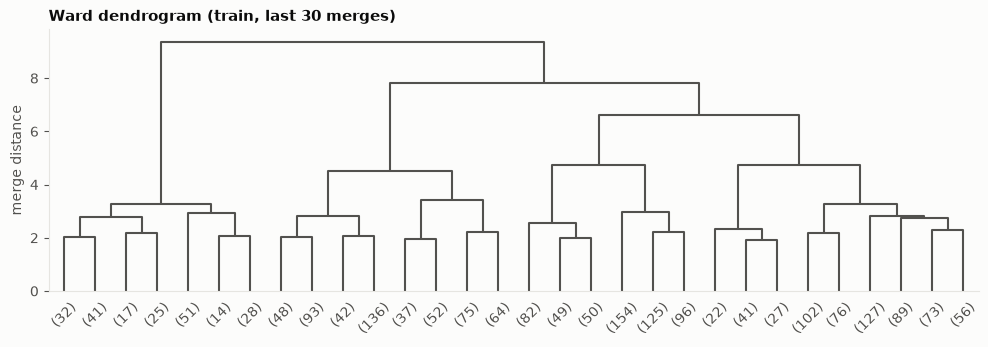

In [13]:
rows = []
for method in ("ward", "average", "complete", "single"):
    clusters = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(Z_train)
    rows.append({"linkage": method, "ARI": adjusted_rand_score(y_train, clusters),
                 "NMI": normalized_mutual_info_score(y_train, clusters),
                 "cluster sizes": sorted(np.bincount(clusters).tolist(), reverse=True)})
display(pd.DataFrame(rows).set_index("linkage").round(3))

fig, ax = plt.subplots(figsize=(12, 3.4))
dendrogram(linkage(Z_train, method="ward"), truncate_mode="lastp", p=30, ax=ax,
           color_threshold=0, above_threshold_color=INK2)
ax.set(title="Ward dendrogram (train, last 30 merges)", ylabel="merge distance")
ax.grid(False)
plt.show()

**Insight.** Solo **Ward** (que une los grupos que menos aumentan la varianza) logra algún acuerdo con las
especies (ARI 0,38), y aun así deja un grupo grande que mezcla especies. `average`, `complete` y `single`
forman un grupo gigante y apartan unos pocos recortes raros: en este espacio no hay "huecos" claros entre
especies, sino un continuo con zonas de mayor densidad.

### 4.3 DBSCAN: densidad y atípicos

DBSCAN agrupa puntos con al menos `min_samples` vecinos dentro de un radio `eps`, y marca el resto como
**ruido**. `eps` se elige con la curva de distancias al décimo vecino (`min_samples = 10`): se prueban varios
percentiles.

,eps,clusters,noise share
eps percentile,,,
50,0.354,1,0.327
70,0.407,1,0.168
80,0.443,1,0.097
90,0.496,1,0.037
95,0.546,1,0.012


Noise crops per species: {'trichuris': 10, 'ascaris': 8, 'hookworm': 6}


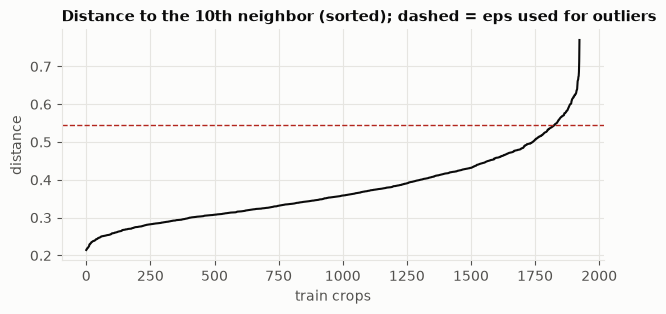

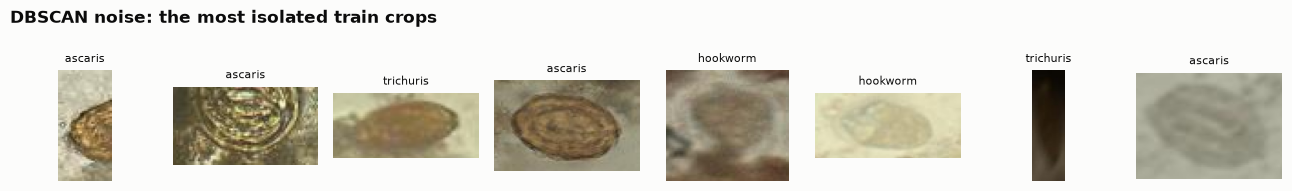

In [14]:
MIN_SAMPLES = 10
tenth_neighbor = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z_train).kneighbors(Z_train)[0][:, -1])
rows = []
for percentile in (50, 70, 80, 90, 95):
    eps = np.percentile(tenth_neighbor, percentile)
    clusters = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Z_train)
    rows.append({"eps percentile": percentile, "eps": eps, "clusters": clusters.max() + 1,
                 "noise share": (clusters == -1).mean()})
display(pd.DataFrame(rows).set_index("eps percentile").round(3))

eps_outliers = np.percentile(tenth_neighbor, 95)
dbscan_labels = DBSCAN(eps=eps_outliers, min_samples=MIN_SAMPLES).fit_predict(Z_train)
noise = np.flatnonzero(dbscan_labels == -1)
print("Noise crops per species:", pd.Series(y_train[noise]).value_counts().to_dict())

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(tenth_neighbor, color=INK)
ax.axhline(eps_outliers, color=ALERT, linestyle="--", linewidth=1)
ax.set(title="Distance to the 10th neighbor (sorted); dashed = eps used for outliers", xlabel="train crops",
       ylabel="distance")
plt.show()

fig, axes = plt.subplots(1, 8, figsize=(13, 1.9))
farthest_noise = noise[np.argsort(-NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z_train)
                                  .kneighbors(Z_train[noise])[0][:, -1])][:8]
for ax, index in zip(axes, farthest_noise):
    show_crop(ax, train_paths[index], y_train[index])
fig.suptitle("DBSCAN noise: the most isolated train crops", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Insight.** Para cualquier `eps`, DBSCAN encuentra **un solo grupo denso** más ruido: las tres especies están
conectadas por zonas de densidad continua y la densidad no las separa. Su utilidad aquí es otra: el ruido (con `eps` en el
percentil 95, 24 recortes) son los recortes **más aislados**: huevos cortados por el borde de la caja, recortes
muy oscuros o muy pálidos y desenfocados. Son candidatos a revisión por un experto. No se borran del entrenamiento (sección 2.2).

**Conclusión del no supervisado.** La estructura natural del embedding coincide solo en parte con las especies
(ARI ≈ 0,3 con 3 grupos y ≈ 0,6 con 4) y mezcla especie con condición de captura. Las etiquetas aportan mucho:
el problema es de **aprendizaje supervisado**, con el no supervisado como herramienta de diagnóstico (atípicos
y cambios de distribución).

## 5. Aprendizaje supervisado: metodología y selección del modelo (3.4, 3.5)

### 5.1 Protocolo

```
train (1924 recortes) ──► GridSearchCV · 5 pliegues StratifiedGroupKFold (agrupado por foto) · F1 macro
                           = elegir hiperparámetros de cada familia
valid (413 recortes)  ──► comparar el mejor de cada familia en datos que ninguna búsqueda vio
                           + umbrales de rechazo (sección 7)
train + valid         ──► re-entrenar el modelo elegido con sus hiperparámetros
test (412 recortes)   ──► evaluación final, UNA sola vez (sección 8)
```

- **Por qué agrupado por foto:** los recortes de una misma foto comparten luz, enfoque y fondo. Si uno cae en
  entrenamiento y otro en validación, el modelo "reconoce la foto".
- **Por qué F1 macro:** pesa igual a las tres especies; ver la sección 7.
- **Alternativas:** las del curso, cada una con lo que la hace distinta: **kNN** (vecindad, sin
  entrenamiento), **árbol de decisión** (reglas interpretables), **Random Forest** (promedio de árboles,
  menos varianza), **Gradient Boosting** (árboles en secuencia que corrigen errores;
  `HistGradientBoostingClassifier`, la implementación por histogramas de sklearn) y **SVM** lineal y con
  kernel RBF (fronteras de máximo margen). Línea base: un clasificador que siempre dice la especie más
  frecuente. Todos van en el mismo `Pipeline`: `StandardScaler → PCA → modelo`.
- **Las grillas** cubren los hiperparámetros que controlan la complejidad de cada modelo (vecinos, profundidad,
  hojas, `C`, número de componentes). Se ampliaron hasta que el mejor valor quedó dentro de la grilla y no en
  el borde.

In [15]:
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)


def make_pipeline(model):
    return Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=SEED)), ("model", model)])


CANDIDATES = {
    "kNN": (KNeighborsClassifier(), {
        "pca__n_components": [32, 64, 128, 256],
        "model__n_neighbors": [5, 11, 21, 31, 51],
        "model__weights": ["uniform", "distance"]}),
    "Decision tree": (DecisionTreeClassifier(random_state=SEED), {
        "pca__n_components": [8, 16, 32, 64],
        "model__max_depth": [5, 10, 20, None],
        "model__min_samples_leaf": [1, 5, 20]}),
    "Random forest": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1), {
        "pca__n_components": [16, 32, 64, 128],
        "model__max_features": ["sqrt", 0.3],
        "model__min_samples_leaf": [1, 3]}),
    "Gradient boosting": (HistGradientBoostingClassifier(max_iter=300, random_state=SEED), {
        "pca__n_components": [16, 32, 64, 128],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [3, None]}),
    "Linear SVM": (SVC(kernel="linear"), {
        "pca__n_components": [64, 128, 256, None],
        "model__C": [0.001, 0.003, 0.01, 0.03, 0.1]}),
    "RBF SVM": (SVC(kernel="rbf", gamma="scale"), {
        "pca__n_components": [64, 128, 256, None],
        "model__C": [1, 3, 10, 30, 100]}),
}

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results, searches = [], {}
results.append({"model": "Baseline (most frequent)",
                "CV F1": cross_val_score(DummyClassifier(strategy="most_frequent"), X_train, y_train,
                                         groups=g_train, cv=cv, scoring="f1_macro").mean(),
                "CV std": 0.0, "train F1": f1_score(y_train, baseline.predict(X_train), average="macro"),
                "valid F1": f1_score(y_valid, baseline.predict(X_valid), average="macro")})
for name, (model, grid) in CANDIDATES.items():
    start = time.perf_counter()
    search = GridSearchCV(make_pipeline(model), grid, scoring="f1_macro", cv=cv, n_jobs=-1,
                          return_train_score=True).fit(X_train, y_train, groups=g_train)
    seconds = time.perf_counter() - start
    best = search.best_index_
    start = time.perf_counter()
    valid_pred = search.predict(X_valid)
    ms_per_crop = 1000 * (time.perf_counter() - start) / len(X_valid)
    searches[name] = search
    results.append({"model": name, "CV F1": search.best_score_,
                    "CV std": search.cv_results_["std_test_score"][best],
                    "train F1": search.cv_results_["mean_train_score"][best],
                    "valid F1": f1_score(y_valid, valid_pred, average="macro"),
                    "configs tried": len(search.cv_results_["params"]),
                    "search s": seconds, "ms / crop": ms_per_crop,
                    "best params": {k.split("__")[1]: v for k, v in search.best_params_.items()}})
results = pd.DataFrame(results).set_index("model")
results["train − CV"] = results["train F1"] - results["CV F1"]
with pd.option_context("display.max_colwidth", 120):
    display(results.round(3))

,CV F1,CV std,train F1,valid F1,configs tried,search s,ms / crop,best params,train − CV
model,,,,,,,,,
Baseline (most frequent),0.168,0.000,0.168,0.169,NaN,NaN,NaN,NaN,-0.000
kNN,0.972,0.007,1.000,0.976,40.0,2.992,0.021,"{'n_neighbors': 21, 'weights': 'distance', 'n_components': 128}",0.028
Decision tree,0.885,0.011,0.992,0.871,48.0,1.063,0.002,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_components': 16}",0.107
Random forest,0.947,0.008,1.000,0.949,16.0,9.690,0.028,"{'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_components': 32}",0.053
Gradient boosting,0.969,0.006,1.000,0.968,16.0,6.600,0.013,"{'learning_rate': 0.1, 'max_depth': 3, 'n_components': 64}",0.031
Linear SVM,0.990,0.003,0.999,0.990,20.0,1.774,0.034,"{'C': 0.003, 'n_components': None}",0.009
RBF SVM,0.986,0.003,1.000,0.990,20.0,2.737,0.047,"{'C': 3, 'n_components': 256}",0.014


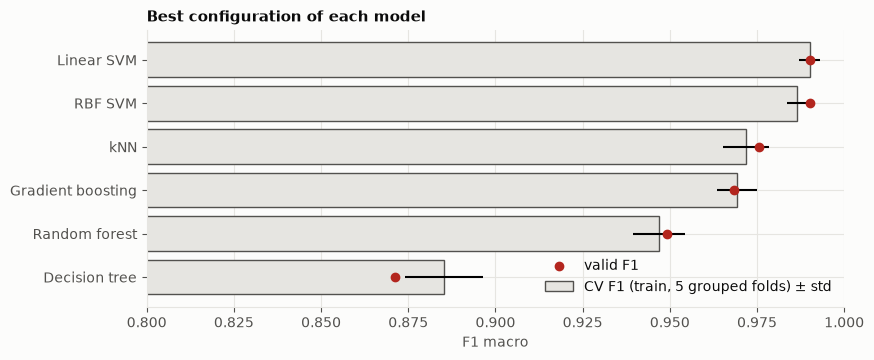

In [16]:
models_only = results.drop(index="Baseline (most frequent)").sort_values("CV F1")
fig, ax = plt.subplots(figsize=(9, 3.6))
positions = np.arange(len(models_only))
ax.barh(positions, models_only["CV F1"], xerr=models_only["CV std"], color=GRID, edgecolor=INK2,
        label="CV F1 (train, 5 grouped folds) ± std")
ax.scatter(models_only["valid F1"], positions, color=ALERT, zorder=3, label="valid F1")
ax.set_yticks(positions, models_only.index)
ax.set(xlim=(0.8, 1.0), xlabel="F1 macro", title="Best configuration of each model")
ax.legend(loc="lower right")
plt.show()

### 5.2 ¿`cls` o `patch_mean`?

DINOv2 da dos resúmenes de cada recorte: el token **CLS** y el **promedio de los parches**. El EDA de los
embeddings mostró que la pureza de vecinos es mayor con `cls`. Se confirma con la validación cruzada de las dos
mejores familias, con sus hiperparámetros elegidos, sobre `cls`, `patch_mean` y los dos concatenados.

In [17]:
top_two = results.drop(index="Baseline (most frequent)")["CV F1"].nlargest(2).index.tolist()
feature_sets = {"cls": X_cls, "patch_mean": X_patch, "cls + patch_mean": np.hstack([X_cls, X_patch])}
rows = []
for name in top_two:
    for feature_name, features in feature_sets.items():
        estimator = clone(searches[name].best_estimator_)
        scores = cross_val_score(estimator, features[is_train], y_train, groups=g_train, cv=cv,
                                 scoring="f1_macro", n_jobs=-1)
        rows.append({"model": name, "features": feature_name, "CV F1": scores.mean(), "CV std": scores.std()})
display(pd.DataFrame(rows).pivot(index="features", columns="model", values="CV F1").round(4))

model,Linear SVM,RBF SVM
features,,
cls,0.990,0.987
cls + patch_mean,0.988,0.989
patch_mean,0.983,0.982


### 5.3 Elección

**Regla de decisión** (fijada antes de mirar `test`): el modelo con mejor F1 macro en la validación cruzada;
si otro queda a menos de una desviación estándar, se prefiere el más simple y rápido, y se verifica que el
resultado se sostenga en `valid`. Además, para el uso real se necesita que el modelo entregue una
**probabilidad** por especie (para el aviso "consulte a un experto").

In [18]:
ranking = results.drop(index="Baseline (most frequent)").sort_values("CV F1", ascending=False)
best_name = ranking.index[0]
within_one_std = ranking[ranking["CV F1"] >= ranking["CV F1"].iloc[0] - ranking["CV std"].iloc[0]]
print("Best in CV:", best_name)
print("Within one std of the best:", within_one_std.index.tolist())
display(within_one_std[["CV F1", "CV std", "valid F1", "ms / crop", "best params"]].round(4))

# Simplicity order used to break ties (fewer hyperparameters, linear boundary first)
SIMPLICITY = ["Linear SVM", "kNN", "RBF SVM", "Decision tree", "Random forest", "Gradient boosting"]
CHOSEN = min(within_one_std.index, key=SIMPLICITY.index)
chosen_params = searches[CHOSEN].best_params_
print(f"\nChosen model: {CHOSEN} with {chosen_params}")

Best in CV: Linear SVM
Within one std of the best: ['Linear SVM']


,CV F1,CV std,valid F1,ms / crop,best params
model,,,,,
Linear SVM,0.99,0.003,0.99,0.034,"{'C': 0.003, 'n_components': None}"



Chosen model: Linear SVM with {'model__C': 0.003, 'pca__n_components': None}


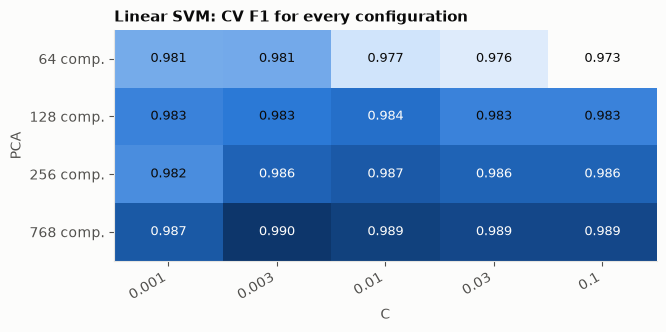

In [19]:
# Sensitivity of the chosen model to its hyperparameters (mean CV F1 of every configuration tried)
chosen_cv = pd.DataFrame(searches[CHOSEN].cv_results_["params"]).assign(
    cv_f1=searches[CHOSEN].cv_results_["mean_test_score"])
chosen_cv["pca__n_components"] = chosen_cv["pca__n_components"].fillna(768).astype(int)
other_param = [c for c in chosen_cv.columns if c.startswith("model__")][0]
# best CV F1 over the remaining hyperparameters (if any), for every PCA size and value of `other_param`
sensitivity = chosen_cv.pivot_table(index="pca__n_components", columns=other_param, values="cv_f1", aggfunc="max")
fig, ax = plt.subplots(figsize=(7, 3))
draw_heatmap(ax, sensitivity.rename(index=lambda n: f"{n} comp."), f"{CHOSEN}: CV F1 for every configuration",
             fmt="{:.3f}")
ax.set(xlabel=other_param.split("__")[1], ylabel="PCA")
plt.show()

**Decisión: SVM lineal, `C = 0,003`, sin reducir dimensiones.**

- **Desempeño:** el mejor F1 macro en validación cruzada (0,990 ± 0,003) y se sostiene en `valid` (0,990). La SVM
  RBF queda a 0,986 y kNN a 0,972. Ningún otro modelo queda a menos de una desviación estándar, así que no hizo
  falta desempatar.
- **Estabilidad:** la tabla de sensibilidad muestra que **todas** las configuraciones probadas quedan entre 0,973 y
  0,990. El resultado no depende de un ajuste fino. Usar las 768 dimensiones (PCA sin recorte: una rotación que no
  cambia nada para un modelo lineal) es algo mejor que reducir, y un `C` pequeño (mucha regularización, margen
  amplio) es lo que mejor generaliza.
- **Por qué tiene sentido:** DINOv2 ya hace el trabajo difícil (convertir la imagen en un vector donde la morfología
  está bien representada); encima, una frontera **lineal** basta y es el modelo con menos capacidad de sobreajustar
  (brecha entrenamiento–validación de 0,9 puntos, la menor de todas).
- **Uso real:** predice en ~0,03 ms por recorte, ocupa poco y da probabilidades con la escala de Platt (sección 7.3).
- **Features:** `cls` es la mejor representación para la SVM lineal (0,990 contra 0,983 con `patch_mean`);
  concatenar las dos no mejora.

## 6. Generalización (3.6)

La pregunta es si el desempeño se mantiene en datos que el modelo no vio, y si no es producto de sobreajuste,
de fuga o de un atajo. Se responde con seis evidencias.

### 6.1 Sobreajuste: entrenamiento contra validación cruzada

In [20]:
gap = results.drop(index="Baseline (most frequent)")[["train F1", "CV F1", "valid F1", "train − CV"]]
display(gap.sort_values("CV F1", ascending=False).round(3))

,train F1,CV F1,valid F1,train − CV
model,,,,
Linear SVM,0.999,0.990,0.990,0.009
RBF SVM,1.000,0.986,0.990,0.014
kNN,1.000,0.972,0.976,0.028
Gradient boosting,1.000,0.969,0.968,0.031
Random forest,1.000,0.947,0.949,0.053
Decision tree,0.992,0.885,0.871,0.107


Todos los modelos llegan a F1 ≈ 1 en entrenamiento (con 768 dimensiones y ~1900 recortes, separar el
entrenamiento es fácil). Lo que importa es la distancia entre entrenamiento y validación: el **árbol de
decisión** sobreajusta (más de 10 puntos de brecha y peor en `valid`), mientras que las SVM y kNN pierden solo
1–3 puntos y **mantienen en `valid`** (datos que ninguna búsqueda vio) lo que prometía la validación cruzada.

### 6.2 Curva de aprendizaje

¿El modelo elegido necesita más datos o ya se estabilizó? Validación cruzada agrupada con fracciones crecientes
de `train`.

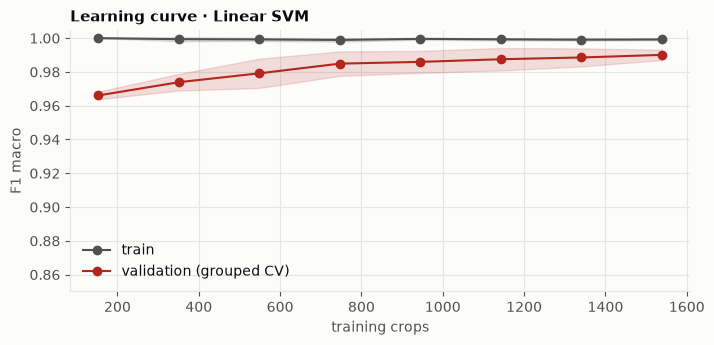

Validation F1 by training size: {153: np.float64(0.966), 351: np.float64(0.974), 549: np.float64(0.979), 747: np.float64(0.985), 945: np.float64(0.986), 1143: np.float64(0.988), 1341: np.float64(0.989), 1539: np.float64(0.99)}


In [21]:
chosen_estimator = clone(searches[CHOSEN].best_estimator_)
sizes, train_scores, cv_scores = learning_curve(
    chosen_estimator, X_train, y_train, groups=g_train, cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, shuffle=True, random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 3.4))
for scores, color, label in ((train_scores, INK2, "train"), (cv_scores, ALERT, "validation (grouped CV)")):
    ax.plot(sizes, scores.mean(axis=1), marker="o", color=color, label=label)
    ax.fill_between(sizes, scores.mean(axis=1) - scores.std(axis=1), scores.mean(axis=1) + scores.std(axis=1),
                    color=color, alpha=0.15)
ax.set(title=f"Learning curve · {CHOSEN}", xlabel="training crops", ylabel="F1 macro", ylim=(0.85, 1.005))
ax.legend()
plt.show()
print("Validation F1 by training size:", dict(zip(sizes.tolist(), cv_scores.mean(axis=1).round(3))))

### 6.3 Fuga: partición agrupada y escalado dentro del pliegue

Tres garantías contra la fuga, ya aplicadas:

1. **Partición por foto original** (no hay foto repartida en dos particiones; verificado en la sección 2).
2. **Escalado y PCA dentro del `Pipeline`**: se ajustan solo con los pliegues de entrenamiento.
3. **`test` congelado** hasta la sección 8.

Para dimensionar el riesgo, se compara la validación cruzada agrupada con una que ignora las fotos
(`StratifiedKFold`). Como casi todas las fotos tienen un solo huevo, se espera poca diferencia; la agrupación
sigue siendo necesaria cuando se agreguen fotos de campo con varios huevos.

In [22]:
grouped = cross_val_score(chosen_estimator, X_train, y_train, groups=g_train, cv=cv, scoring="f1_macro", n_jobs=-1)
ungrouped = cross_val_score(chosen_estimator, X_train, y_train,
                            cv=StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED), scoring="f1_macro",
                            n_jobs=-1)
print(f"Grouped by photo: {grouped.mean():.4f} ± {grouped.std():.4f}")
print(f"Ignoring photos:  {ungrouped.mean():.4f} ± {ungrouped.std():.4f}")

Grouped by photo: 0.9901 ± 0.0031
Ignoring photos:  0.9906 ± 0.0021


### 6.4 Detector de atajos: un modelo que no ve el huevo

Un modelo de control solo recibe medidas de **captura**: brillo, contraste y calidez del recorte, tamaño de la
caja y relación ancho/alto. Si acertara casi tanto como el modelo con embeddings, el embedding podría estar
usando esas pistas en vez de la morfología.

In [23]:
capture_features = pixel_stats.assign(box_size=box_size.to_numpy(), log_aspect=log_aspect.to_numpy(),
                                      abs_log_aspect=np.abs(log_aspect.to_numpy()))
shortcut_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)
shortcut_cv = cross_val_score(shortcut_model, capture_features[is_train], y_train, groups=g_train, cv=cv,
                              scoring="f1_macro")
shortcut_model.fit(capture_features[is_train], y_train)
shortcut_valid = f1_score(y_valid, shortcut_model.predict(capture_features[is_valid]), average="macro")
print(f"Capture-only model: CV F1 {shortcut_cv.mean():.3f} ± {shortcut_cv.std():.3f} | valid F1 {shortcut_valid:.3f}")
print(f"Chosen model ({CHOSEN}): CV F1 {results.loc[CHOSEN, 'CV F1']:.3f} | valid F1 {results.loc[CHOSEN, 'valid F1']:.3f}")
print("Chance level (3 balanced classes): ~0.33")

Capture-only model: CV F1 0.704 ± 0.026 | valid F1 0.698
Chosen model (Linear SVM): CV F1 0.990 | valid F1 0.990
Chance level (3 balanced classes): ~0.33


**Resultado e interpretación.** El modelo de control llega a **F1 0,70**, muy por encima del azar (0,33) y muy por
debajo del modelo con embeddings (0,99). Hay entonces información de la especie en las condiciones de captura y
en el tamaño. En la sección 9 SHAP muestra que la variable que más pesa es el **tamaño de la caja**, seguida por la
forma (`|log aspecto|`) y el color. Las dos primeras son en buena parte biología (*Trichuris* es alargado y en
estas fotos más pequeño); el color sí es un posible atajo.

Tres razones para pensar que el clasificador no depende de esas pistas: (1) cada recorte se lleva a 224 × 224, así
que el tamaño absoluto **no** le llega a DINOv2; (2) el modelo con embeddings supera al de control por 29 puntos,
y lo que aporta encima es la morfología (sección 9: sus componentes principales separan forma, cáscara y
contenido); (3) en la prueba de robustez (6.5) alterar el brillo, el contraste o el color cambia el F1 en menos de
1 punto. La comprobación definitiva es la prueba con fotos externas, pendiente.

### 6.5 Robustez: ¿qué pasa si la foto viene peor?

No hay todavía fotos externas de celular con las especies confirmadas (pendientes de la UPB). Para anticipar el
cambio de dominio, se alteran los recortes de `valid` como lo haría una foto de celular por el ocular (luz,
enfoque, compresión, tinción), se vuelven a pasar por DINOv2 y se clasifican con el modelo elegido entrenado
en `train`.

,valid F1,recall ascaris,recall hookworm,recall trichuris,median similarity to train,drop (points)
perturbation,,,,,,
original,0.990,0.993,1.000,0.978,0.919,0.000
darker (×0.6),0.993,0.993,1.000,0.985,0.915,-0.248
brighter (×1.4),0.983,0.971,1.000,0.978,0.901,0.730
low contrast (×0.6),0.990,0.993,1.000,0.978,0.914,-0.003
blur (radius 2),0.951,0.882,0.986,0.985,0.842,3.924
blur (radius 4),0.739,0.485,0.907,0.854,0.673,25.119
JPEG quality 15,0.921,0.824,0.979,0.964,0.817,6.896
low resolution (×0.35),0.961,0.904,0.993,0.985,0.846,2.944
warm cast (lugol-like),0.981,0.993,0.993,0.956,0.914,0.969


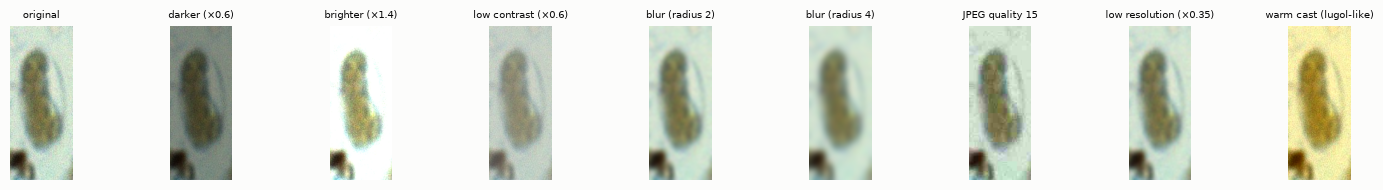

In [24]:
sys.path.insert(0, str(ROOT / "src" / "app"))
from inference import closest_similarity, embed_crops, load_dinov2  # noqa: E402

dinov2 = load_dinov2()


def jpeg(image, quality):
    from io import BytesIO
    buffer = BytesIO()
    image.save(buffer, format="JPEG", quality=quality)
    return Image.open(buffer).convert("RGB")


def warm(image, shift):
    """Shift red up and blue down: yellow-brown cast, like lugol staining or a warm lamp."""
    rgb = np.asarray(image, dtype=np.int16)
    rgb = rgb + np.array([shift, shift // 3, -shift])
    return Image.fromarray(np.clip(rgb, 0, 255).astype(np.uint8))


def low_resolution(image, factor):
    small = image.resize((max(8, int(image.width * factor)), max(8, int(image.height * factor))), Image.BILINEAR)
    return small.resize(image.size, Image.BILINEAR)


PERTURBATIONS = {
    "original": lambda im: im,
    "darker (×0.6)": lambda im: ImageEnhance.Brightness(im).enhance(0.6),
    "brighter (×1.4)": lambda im: ImageEnhance.Brightness(im).enhance(1.4),
    "low contrast (×0.6)": lambda im: ImageEnhance.Contrast(im).enhance(0.6),
    "blur (radius 2)": lambda im: im.filter(ImageFilter.GaussianBlur(2)),
    "blur (radius 4)": lambda im: im.filter(ImageFilter.GaussianBlur(4)),
    "JPEG quality 15": lambda im: jpeg(im, 15),
    "low resolution (×0.35)": lambda im: low_resolution(im, 0.35),
    "warm cast (lugol-like)": lambda im: warm(im, 40),
}

robust_model = clone(searches[CHOSEN].best_estimator_).fit(X_train, y_train)
unit_train = to_unit(X_train)
valid_images = [Image.open(ROOT / path).convert("RGB") for path in crops.crop_path[is_valid]]
perturbed_vectors, rows = {}, []
for name, perturb in PERTURBATIONS.items():
    vectors = embed_crops(dinov2, [perturb(image) for image in valid_images])
    perturbed_vectors[name] = vectors
    prediction = robust_model.predict(vectors)
    rows.append({"perturbation": name, "valid F1": f1_score(y_valid, prediction, average="macro"),
                 **{f"recall {c}": (prediction[y_valid == c] == c).mean() for c in CLASSES},
                 "median similarity to train": np.median(closest_similarity(vectors, unit_train))})
robustness = pd.DataFrame(rows).set_index("perturbation")
robustness["drop (points)"] = 100 * (robustness.loc["original", "valid F1"] - robustness["valid F1"])
display(robustness.round(3))

fig, axes = plt.subplots(1, len(PERTURBATIONS), figsize=(15, 2))
example = valid_images[int(np.flatnonzero(y_valid == "hookworm")[0])]
for ax, (name, perturb) in zip(axes, PERTURBATIONS.items()):
    ax.imshow(perturb(example))
    ax.set_title(name, fontsize=7, loc="center", fontweight="normal")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Resultado.** El modelo es **robusto a la luz y al color**: oscurecer, aclarar, bajar el contraste o dar un tinte
cálido tipo lugol cambia el F1 en menos de 1 punto. Es **sensible a la nitidez**: un desenfoque leve (radio 2)
cuesta 4 puntos, la compresión JPEG fuerte 7 y un desenfoque fuerte (radio 4) 25. La especie que más sufre es
*Ascaris*, cuya cáscara mamelonada es justamente un detalle fino. Dos consecuencias para el despliegue: (1) el
protocolo de captura debe pedir fotos **enfocadas** y sin compresión de mensajería; (2) la similitud mediana con el
entrenamiento cae justo en los casos que empeoran (de 0,92 a 0,84, 0,82 y 0,67), así que sirve para **detectar**
el problema sin etiquetas (sección 11).

### 6.6 De punta a punta: recortes del detector en vez de cajas dibujadas

En uso real el clasificador no recibe la caja dibujada por un humano sino la de YOLO, que puede quedar
corrida, más grande o más chica, o caer sobre algo que no es un huevo. Se toman las detecciones de YOLO en las
410 fotos de `valid` (umbral 0,25) y se clasifican con el modelo entrenado en `train`.

YOLO detections in valid (score >= 0.25): 416 = 412 eggs + 4 false alarms
F1 macro on hand-drawn crops: 0.9903
F1 macro on YOLO crops of real eggs: 0.9927
What the false alarms were called: {'ascaris': 3, 'hookworm': 1}


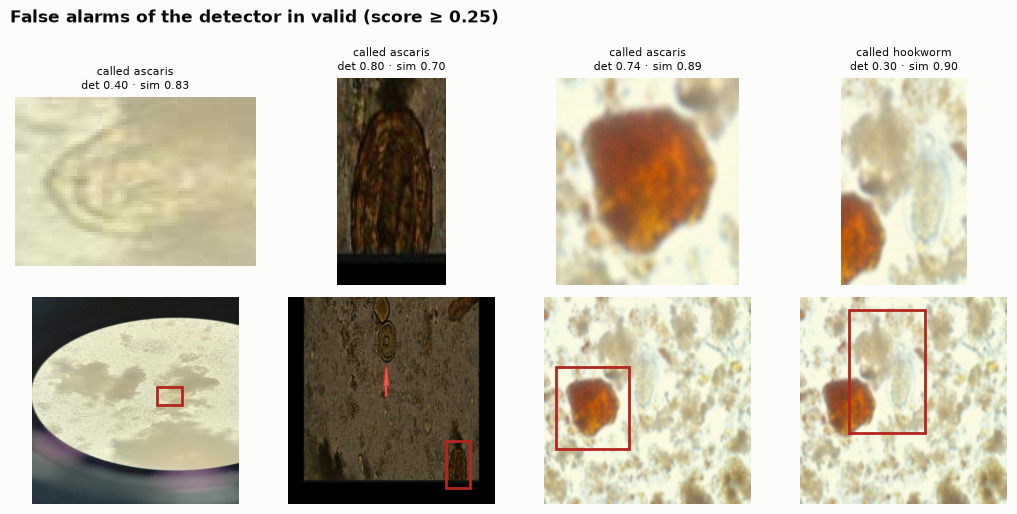

In [25]:
det_valid, det_valid_cls, _ = load_embeddings(*DETECTED["valid"])
keep = (det_valid.det_conf >= DET_CONF).to_numpy()
det_valid, det_valid_cls = det_valid[keep].reset_index(drop=True), det_valid_cls[keep]
is_egg_valid = (det_valid.label != "none").to_numpy()
det_valid_pred = robust_model.predict(det_valid_cls)
print(f"YOLO detections in valid (score >= {DET_CONF}): {len(det_valid)} "
      f"= {is_egg_valid.sum()} eggs + {(~is_egg_valid).sum()} false alarms")
print(f"F1 macro on hand-drawn crops: {results.loc[CHOSEN, 'valid F1']:.4f}")
print(f"F1 macro on YOLO crops of real eggs: "
      f"{f1_score(det_valid.label[is_egg_valid], det_valid_pred[is_egg_valid], average='macro'):.4f}")
print("What the false alarms were called:", pd.Series(det_valid_pred[~is_egg_valid]).value_counts().to_dict())


def show_false_alarms(detections, vectors, species, reference, title):
    """The detector's false alarms next to the whole photo, to judge them by eye."""
    alarms = np.flatnonzero((detections.label == "none").to_numpy())
    similarity = closest_similarity(vectors[alarms], reference)
    fig, axes = plt.subplots(2, len(alarms), figsize=(2.6 * len(alarms), 5.2), squeeze=False)
    for col, (index, sim) in enumerate(zip(alarms, similarity)):
        row = detections.iloc[index]
        show_crop(axes[0, col], row.crop_path, f"called {species[index]}\ndet {row.det_conf:.2f} · sim {sim:.2f}")
        axes[1, col].imshow(Image.open(ROOT / row.source_image))
        axes[1, col].add_patch(plt.Rectangle((row.x1, row.y1), row.x2 - row.x1, row.y2 - row.y1, fill=False,
                                             edgecolor=ALERT, linewidth=2))
        axes[1, col].axis("off")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    plt.tight_layout()
    plt.show()


show_false_alarms(det_valid, det_valid_cls, det_valid_pred, unit_train, "False alarms of the detector in valid (score ≥ 0.25)")

El clasificador funciona igual con las cajas de YOLO que con las dibujadas a mano (F1 0,993 contra 0,990): las
cajas del detector no le quitan información. Las **falsas alarmas** del detector reciben forzosamente una especie
(el modelo no tiene clase "no es huevo"). Mirándolas, no todas son errores claros: una es un huevo grande cortado
por el borde del campo y otra encierra un objeto ovalado pálido; las otras son un grumo café y una forma
desenfocada. Sin un experto no se puede decidir; quedan para revisión de la UPB. Para estos casos está el
**rechazo** de la sección 7.4.

## 7. Métricas de desempeño (3.7)

### 7.1 Qué se mide y por qué

| Métrica | Qué significa en el uso real | Por qué esta |
|---|---|---|
| **F1 macro** (principal) | Promedio, por especie, del equilibrio entre no inventar huevos de esa especie (precisión) y no perderlos (recall) | Las tres especies importan igual para el tratamiento; la exactitud global escondería una especie mal clasificada |
| **Recall por especie** | De los huevos reales de una especie, cuántos se reconocen | Un huevo de *Trichuris* llamado *Ascaris* cambia el conteo de las dos especies y la intensidad estimada |
| **Matriz de confusión** | Qué especie se confunde con cuál | Muestra el error clínico concreto (p. ej. *Ascaris* ↔ uncinaria) |
| Exactitud balanceada | Promedio de los recall | Control: con clases balanceadas debe coincidir con la exactitud |
| **Intervalo por bootstrap** | Rango plausible del F1 con otro conjunto de fotos | Con ~400 recortes por partición, una diferencia de 0,5 puntos puede ser azar |
| **Cobertura y error con rechazo** | Qué parte de los huevos se cuenta sola y qué parte va a revisión del experto | Sustenta el aviso "consulte a un experto" |
| **Error de conteo por foto** | Cuántos huevos de cada especie de más o de menos | Es lo que alimenta el HPG (conteo × 24): un huevo perdido en una lámina vale 24 HPG |
| Recall del detector | Huevos que el detector encuentra | Un huevo que no se detecta no se puede clasificar: es un falso negativo clínico |

### 7.2 Modelo elegido en `valid`

              precision    recall  f1-score   support

     ascaris      0.978     0.993     0.985       136
    hookworm      0.993     1.000     0.996       140
   trichuris      1.000     0.978     0.989       137

    accuracy                          0.990       413
   macro avg      0.990     0.990     0.990       413
weighted avg      0.990     0.990     0.990       413



Balanced accuracy: 0.9902


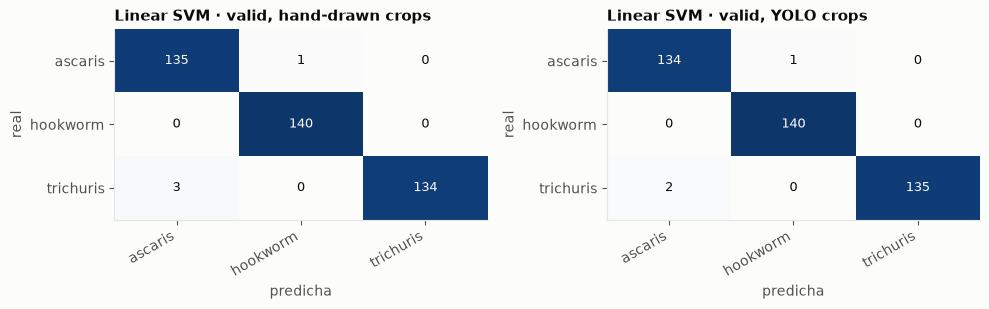

In [26]:
valid_pred = robust_model.predict(X_valid)
print(classification_report(y_valid, valid_pred, digits=3))
print("Balanced accuracy:", round(balanced_accuracy_score(y_valid, valid_pred), 4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
draw_confusion(axes[0], y_valid, valid_pred, f"{CHOSEN} · valid, hand-drawn crops")
draw_confusion(axes[1], det_valid.label[is_egg_valid], det_valid_pred[is_egg_valid], f"{CHOSEN} · valid, YOLO crops")
plt.tight_layout()
plt.show()

In [27]:
def bootstrap_f1(y_true, y_pred, photo_groups, n_rounds=2000, seed=SEED):
    """95 % interval of F1 macro, resampling whole photos (eggs of a photo stay together)."""
    generator = np.random.default_rng(seed)
    unique_groups, inverse = np.unique(photo_groups, return_inverse=True)
    members = [np.flatnonzero(inverse == g) for g in range(len(unique_groups))]
    scores = []
    for _ in range(n_rounds):
        chosen = np.concatenate([members[g] for g in generator.integers(0, len(members), len(members))])
        scores.append(f1_score(y_true[chosen], y_pred[chosen], average="macro"))
    return np.percentile(scores, [2.5, 97.5])


low, high = bootstrap_f1(y_valid, valid_pred, g_valid)
print(f"Valid F1 macro {f1_score(y_valid, valid_pred, average='macro'):.4f}  (95 % bootstrap interval {low:.4f} – {high:.4f})")

Valid F1 macro 0.9903  (95 % bootstrap interval 0.9802 – 0.9977)


### 7.3 Probabilidades

El aviso "consulte a un experto" necesita una probabilidad por especie. Las SVM no la dan directamente; con
`probability=True` sklearn la estima con la escala de Platt (una regresión logística sobre la distancia a la
frontera, ajustada con validación cruzada interna). kNN la da como la proporción de vecinos de cada especie.

In [28]:
probabilistic_model = clone(searches[CHOSEN].best_estimator_)
if isinstance(probabilistic_model.named_steps["model"], SVC):
    probabilistic_model.set_params(model__probability=True, model__random_state=SEED)
probabilistic_model.fit(X_train, y_train)
valid_proba = probabilistic_model.predict_proba(X_valid)
valid_confidence = valid_proba.max(axis=1)
valid_correct = probabilistic_model.classes_[valid_proba.argmax(axis=1)] == y_valid

# Reliability: when the model says p, is it right about p of the time?
bins = np.array([0.0, 0.6, 0.8, 0.9, 0.95, 0.99, 1.0001])
reliability = pd.DataFrame({"confidence": valid_confidence, "correct": valid_correct})
reliability["bin"] = pd.cut(reliability.confidence, bins, right=False)
display(reliability.groupby("bin", observed=True).agg(crops=("correct", "size"), mean_confidence=("confidence", "mean"),
                                                      accuracy=("correct", "mean")).round(3))

,crops,mean_confidence,accuracy
bin,,,
"[0.0, 0.6)",2,0.563,1.000
"[0.6, 0.8)",8,0.682,0.750
"[0.8, 0.9)",6,0.855,1.000
"[0.9, 0.95)",11,0.927,0.909
"[0.95, 0.99)",24,0.979,1.000
"[0.99, 1.0)",362,0.999,1.000


### 7.4 Rechazo: cuándo decir "consulte a un experto"

Dos señales, calculadas para cada huevo detectado:

- **Confianza** = probabilidad de la especie elegida. Baja → el huevo está en la frontera entre dos especies.
- **Similitud** = similitud coseno con el recorte más parecido del entrenamiento. Baja → el recorte no se parece
  a nada conocido: una falsa alarma del detector, una tinción o un microscopio nuevos.

Un huevo es **"dudoso"** si cualquiera de las dos queda bajo su umbral; los dudosos no se suman solos al conteo:
se muestran aparte para que el usuario los revise. **Criterio de los umbrales** (sobre las detecciones de YOLO en
`valid`, con referencia `train`): cada umbral es el **percentil 1** de esa señal entre los huevos reales, es decir,
se acepta mandar a revisión ~1 % de los huevos verdaderos por cada señal a cambio de atrapar errores y falsas
alarmas. Se eligió así porque un huevo revisado de más cuesta segundos al microscopista, mientras que un huevo
mal contado cambia el HPG en 24.

Confidence threshold: 0.681 | similarity threshold: 0.715


,detections,counted automatically,sent to review
"egg, right species",409,401,8
"egg, wrong species",3,1,2
false alarm (no egg),4,3,1


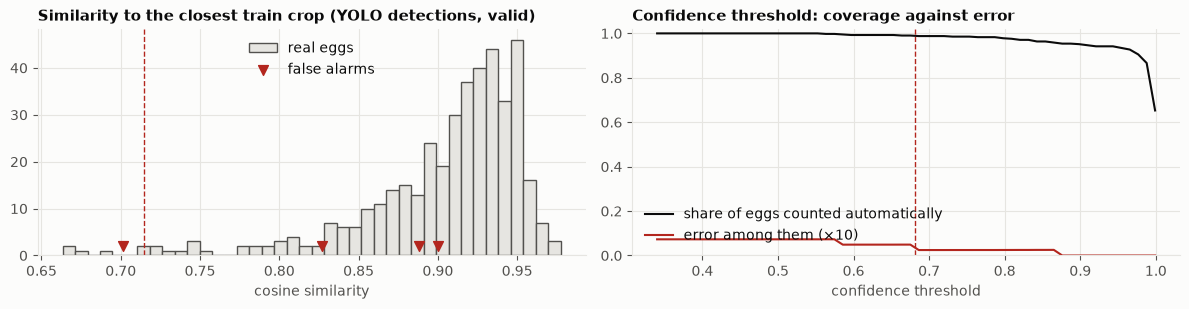

In [29]:
det_valid_proba = probabilistic_model.predict_proba(det_valid_cls)
det_valid_confidence = det_valid_proba.max(axis=1)
det_valid_species = probabilistic_model.classes_[det_valid_proba.argmax(axis=1)]
det_valid_similarity = closest_similarity(det_valid_cls, unit_train)

CONF_THRESHOLD = float(np.percentile(det_valid_confidence[is_egg_valid], 1))
SIMILARITY_THRESHOLD = float(np.percentile(det_valid_similarity[is_egg_valid], 1))
print(f"Confidence threshold: {CONF_THRESHOLD:.3f} | similarity threshold: {SIMILARITY_THRESHOLD:.3f}")


def rejection_summary(is_egg, true_label, species, confidence, similarity):
    """What the two thresholds do to real eggs (right or wrong species) and to false alarms."""
    doubtful = (confidence < CONF_THRESHOLD) | (similarity < SIMILARITY_THRESHOLD)
    right = is_egg & (species == true_label)
    wrong = is_egg & (species != true_label)
    return pd.DataFrame({
        "detections": [right.sum(), wrong.sum(), (~is_egg).sum()],
        "counted automatically": [(right & ~doubtful).sum(), (wrong & ~doubtful).sum(), (~is_egg & ~doubtful).sum()],
        "sent to review": [(right & doubtful).sum(), (wrong & doubtful).sum(), (~is_egg & doubtful).sum()],
    }, index=["egg, right species", "egg, wrong species", "false alarm (no egg)"])


display(rejection_summary(is_egg_valid, det_valid.label.to_numpy(), det_valid_species, det_valid_confidence,
                          det_valid_similarity))

fig, (ax_sim, ax_conf) = plt.subplots(1, 2, figsize=(12, 3.2))
ax_sim.hist(det_valid_similarity[is_egg_valid], bins=40, color=GRID, edgecolor=INK2, label="real eggs")
ax_sim.scatter(det_valid_similarity[~is_egg_valid], np.full((~is_egg_valid).sum(), 2), color=ALERT, zorder=3,
               marker="v", s=50, label="false alarms")
ax_sim.axvline(SIMILARITY_THRESHOLD, color=ALERT, linestyle="--", linewidth=1)
ax_sim.set(title="Similarity to the closest train crop (YOLO detections, valid)", xlabel="cosine similarity")
ax_sim.legend()
thresholds = np.linspace(0.34, 0.999, 60)
coverage = [(det_valid_confidence[is_egg_valid] >= t).mean() for t in thresholds]
accepted_error = [1 - ((det_valid_species == det_valid.label.to_numpy())[is_egg_valid & (det_valid_confidence >= t)]).mean()
                  for t in thresholds]
ax_conf.plot(thresholds, coverage, color=INK, label="share of eggs counted automatically")
ax_conf.plot(thresholds, 10 * np.array(accepted_error), color=ALERT, label="error among them (×10)")
ax_conf.axvline(CONF_THRESHOLD, color=ALERT, linestyle="--", linewidth=1)
ax_conf.set(title="Confidence threshold: coverage against error", xlabel="confidence threshold", ylim=(0, 1.02))
ax_conf.legend(loc="lower left")
plt.tight_layout()
plt.show()

**Resultado en `valid`.** Con umbrales de confianza 0,68 y similitud 0,71:

- De los 412 huevos reales detectados, **402 se cuentan solos** (401 con la especie correcta y 1 equivocada) y 10
  van a revisión. De esos 10, 2 eran errores de especie: el rechazo atrapa 2 de los 3 errores.
- De las 4 falsas alarmas, solo 1 cae bajo el umbral de similitud. Las otras se parecen a huevos (similitud de
  0,83 a 0,90): son grumos ovalados o huevos sin anotar.

**Conclusión.** El rechazo sirve para los errores de especie y para los cambios de captura (sección 11), pero
**no reemplaza** una clase "no es huevo". Por eso el conteo siempre se presenta para que el usuario vea cada caja,
y la clase "otro / sin parásito" queda como la mejora prioritaria.

La tabla de confiabilidad muestra que las probabilidades son razonables: por encima de 0,95 el modelo acierta en
todos los casos (386 de 386), y todos los errores tienen confianza menor a 0,95.

## 8. Evaluación final en `test` (3.6) — una sola vez

Hasta aquí `test` no se usó. El modelo elegido se re-entrena con `train + valid` (los mismos hiperparámetros) y
se evalúa **una sola vez**, con los umbrales de rechazo ya fijados en `valid`. La referencia para la similitud
pasa a ser `train + valid`. Se evalúa de dos formas: con las cajas dibujadas a mano (clasificador solo) y de
punta a punta con las detecciones de YOLO en las 409 fotos de `test` (sistema completo, incluido el conteo por
foto).

In [30]:
is_test = (all_crops.split == "test").to_numpy()
X_test, y_test, g_test = all_cls[is_test], all_crops.label.to_numpy()[is_test], all_crops.group.to_numpy()[is_test]

final_model = clone(probabilistic_model).fit(X_cls, y)   # train + valid
unit_reference = to_unit(X_cls)

test_pred = final_model.predict(X_test)
low, high = bootstrap_f1(y_test, test_pred, g_test)
print("Hand-drawn test crops")
print(classification_report(y_test, test_pred, digits=3))
print(f"F1 macro {f1_score(y_test, test_pred, average='macro'):.4f}  (95 % bootstrap interval {low:.4f} – {high:.4f})")

Hand-drawn test crops
              precision    recall  f1-score   support

     ascaris      0.993     1.000     0.996       138
    hookworm      1.000     0.993     0.996       138
   trichuris      1.000     1.000     1.000       136

    accuracy                          0.998       412
   macro avg      0.998     0.998     0.998       412
weighted avg      0.998     0.998     0.998       412

F1 macro 0.9976  (95 % bootstrap interval 0.9925 – 1.0000)


YOLO on the 409 test photos with detections: 415 detections = 411 of 412 real eggs + 4 false alarms
F1 macro on YOLO crops of real eggs: 0.9976


,detections,counted automatically,sent to review
"egg, right species",410,402,8
"egg, wrong species",1,0,1
false alarm (no egg),4,4,0


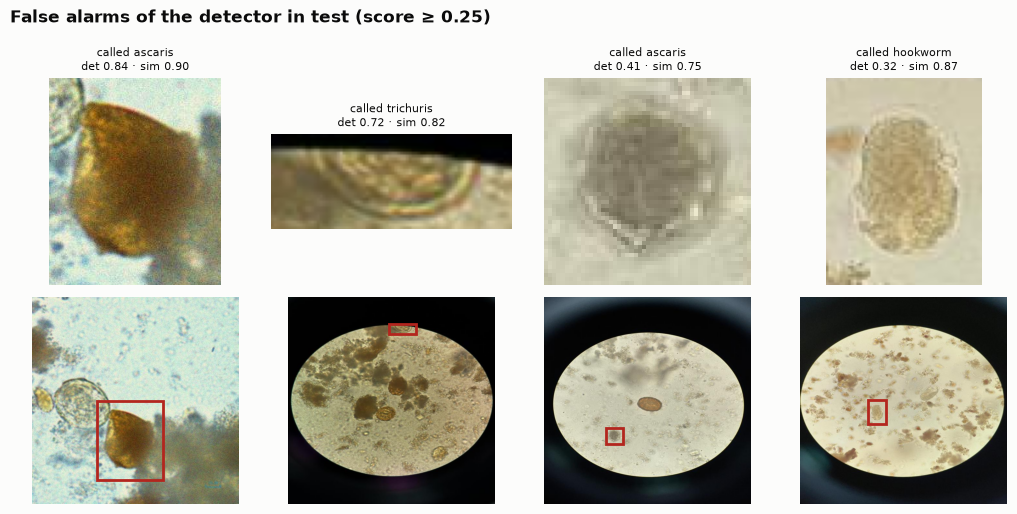

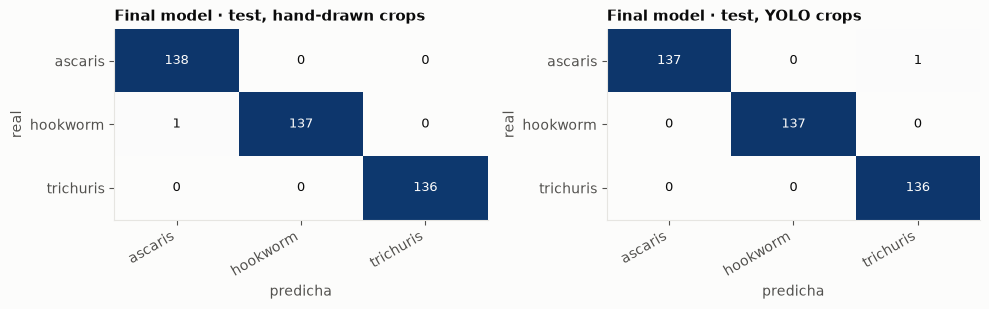

In [31]:
det_test, det_test_cls, _ = load_embeddings(*DETECTED["test"])
keep = (det_test.det_conf >= DET_CONF).to_numpy()
det_test, det_test_cls = det_test[keep].reset_index(drop=True), det_test_cls[keep]
is_egg_test = (det_test.label != "none").to_numpy()
det_test_proba = final_model.predict_proba(det_test_cls)
det_test_confidence = det_test_proba.max(axis=1)
det_test_species = final_model.classes_[det_test_proba.argmax(axis=1)]
det_test_similarity = closest_similarity(det_test_cls, unit_reference)
test_doubtful = (det_test_confidence < CONF_THRESHOLD) | (det_test_similarity < SIMILARITY_THRESHOLD)

real_eggs_test = len(all_crops[is_test])
print(f"YOLO on the {det_test.source_image.nunique()} test photos with detections: {len(det_test)} detections "
      f"= {is_egg_test.sum()} of {real_eggs_test} real eggs + {(~is_egg_test).sum()} false alarms")
print(f"F1 macro on YOLO crops of real eggs: "
      f"{f1_score(det_test.label[is_egg_test], det_test_species[is_egg_test], average='macro'):.4f}")
display(rejection_summary(is_egg_test, det_test.label.to_numpy(), det_test_species, det_test_confidence,
                          det_test_similarity))

show_false_alarms(det_test, det_test_cls, det_test_species, unit_reference, "False alarms of the detector in test (score ≥ 0.25)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
draw_confusion(axes[0], y_test, test_pred, "Final model · test, hand-drawn crops")
draw_confusion(axes[1], det_test.label[is_egg_test], det_test_species[is_egg_test], "Final model · test, YOLO crops")
plt.tight_layout()
plt.show()

**Conteo por foto.** Lo que ve el usuario: cuántos huevos de cada especie cuenta el sistema en cada foto,
comparado con la verdad. Se cuentan solo los huevos aceptados automáticamente (los dudosos van a revisión).

In [32]:
test_photos = pd.Series(all_crops.source_image[is_test].unique(), name="source_image")
truth = (all_crops[is_test].groupby(["source_image", "label"]).size().unstack(fill_value=0)
         .reindex(index=test_photos, columns=CLASSES, fill_value=0))
counted = (det_test[~test_doubtful].assign(species=det_test_species[~test_doubtful])
           .groupby(["source_image", "species"]).size().unstack(fill_value=0)
           .reindex(index=test_photos, columns=CLASSES, fill_value=0))
review = det_test[test_doubtful].groupby("source_image").size().reindex(test_photos, fill_value=0)
exact = (counted == truth).all(axis=1)
print(f"Photos: {len(test_photos)} | exact count of every species: {exact.mean():.1%}")
print(f"Photos with something sent to review: {(review > 0).sum()}")
print(f"Exact or with the difference sent to review: {(exact | (review > 0)).mean():.1%}")
print("Mean absolute count error per photo and species:", (counted - truth).abs().mean().round(4).to_dict())
print("Total eggs — real:", truth.sum().to_dict(), "| counted automatically:", counted.sum().to_dict(),
      "| sent to review:", int(review.sum()))

Photos: 409 | exact count of every species: 96.6%
Photos with something sent to review: 9
Exact or with the difference sent to review: 98.8%
Mean absolute count error per photo and species: {'ascaris': 0.0147, 'hookworm': 0.0098, 'trichuris': 0.0098}
Total eggs — real: {'ascaris': 138, 'hookworm': 138, 'trichuris': 136} | counted automatically: {'ascaris': 136, 'hookworm': 136, 'trichuris': 134} | sent to review: 9


**Resultado final.**

- **Clasificador:** F1 macro **0,998** en `test` (1 error en 412 recortes; intervalo bootstrap 0,993–1,000), sin
  caída frente a `valid` (0,990). La elección del modelo no sobreajustó a `valid`.
- **Sistema completo:** el detector encuentra 411 de 412 huevos y el clasificador acierta la especie en todos
  menos uno (F1 0,998 sobre las cajas de YOLO); el único error de especie fue enviado a revisión.
- **Conteo:** en el **96,6 %** de las 409 fotos el conteo de las tres especies es exacto, y en el 98,8 % es exacto o
  la diferencia quedó marcada como dudosa. El error medio es de 0,01 huevos por foto y especie. De los 412 huevos reales:
  **402 se cuentan solos con la especie correcta**, 9 van a revisión (8 bien clasificados con confianza baja y el
  único error de especie) y 1 no lo encuentra el detector. Además se cuentan 4 falsas alarmas (las de la figura,
  que el rechazo no atrapó), así que el total automático es 406.

**Lectura honesta.** En fotos de Chula el sistema es casi perfecto; el riesgo real está en el cambio de dominio
(fotos de celular del Chocó) y en los objetos parecidos a huevos. Por eso los criterios de éxito del proyecto se
miden con las fotos externas de la UPB, y la app siempre se presenta como **apoyo**.

## 9. Explicabilidad con SHAP

**SHAP** (Lundberg & Lee, 2017) reparte la predicción de un modelo entre sus variables de entrada según los
valores de Shapley: cuánto empujó cada variable hacia una especie u otra, para cada huevo. `TreeExplainer` lo
calcula de forma exacta y rápida para modelos de árboles, así que se aplica a dos modelos de árboles:

1. **Random Forest sobre los componentes del PCA** (el mejor modelo de árboles de la sección 5): qué
   direcciones del embedding usa, y qué significan al mirarlas en los recortes.
2. **El modelo de control de atajos** (sección 6.4): qué condiciones de captura llevan algo de información de
   la especie.

El modelo elegido es una SVM; sus componentes de entrada son los mismos (`StandardScaler → PCA`), así que el
análisis de las direcciones del espacio aplica a los dos.

SHAP values: (413, 32, 3) (valid crops, components, species)


,ascaris,hookworm,trichuris,total
PC2,0.128,0.103,0.231,0.462
PC3,0.075,0.114,0.039,0.228
PC4,0.074,0.092,0.021,0.187
PC5,0.073,0.068,0.012,0.153
PC9,0.044,0.011,0.045,0.100
PC1,0.016,0.026,0.014,0.057
PC6,0.022,0.012,0.010,0.044
PC7,0.018,0.014,0.007,0.038
PC10,0.007,0.014,0.009,0.030
PC13,0.012,0.003,0.011,0.026


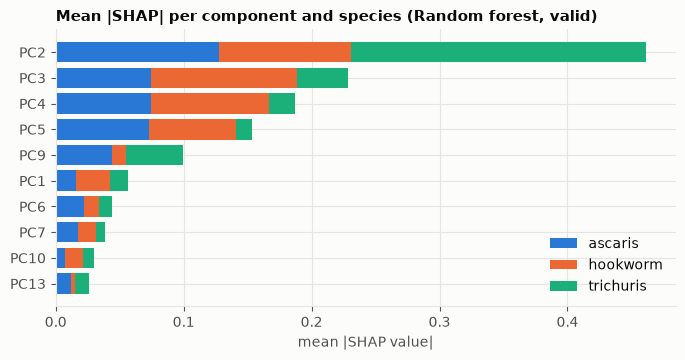

In [33]:
forest = clone(searches["Random forest"].best_estimator_).fit(X_train, y_train)
forest_features = forest[:-1].transform(X_valid)
component_names = [f"PC{i + 1}" for i in range(forest_features.shape[1])]
forest_explainer = shap.TreeExplainer(forest.named_steps["model"])
forest_shap = forest_explainer(pd.DataFrame(forest_features, columns=component_names))
print("SHAP values:", forest_shap.values.shape, "(valid crops, components, species)")

mean_abs = pd.DataFrame(np.abs(forest_shap.values).mean(axis=0), index=component_names,
                        columns=forest.named_steps["model"].classes_)
top_components = mean_abs.sum(axis=1).nlargest(10).index
display(mean_abs.loc[top_components].assign(total=lambda t: t.sum(axis=1)).round(4))
fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(top_components))
for name in CLASSES:
    widths = mean_abs.loc[top_components[::-1], name].to_numpy()
    ax.barh(top_components[::-1], widths, left=left, color=COLORS[name], label=name)
    left += widths
ax.set(title="Mean |SHAP| per component and species (Random forest, valid)", xlabel="mean |SHAP value|")
ax.legend()
plt.show()

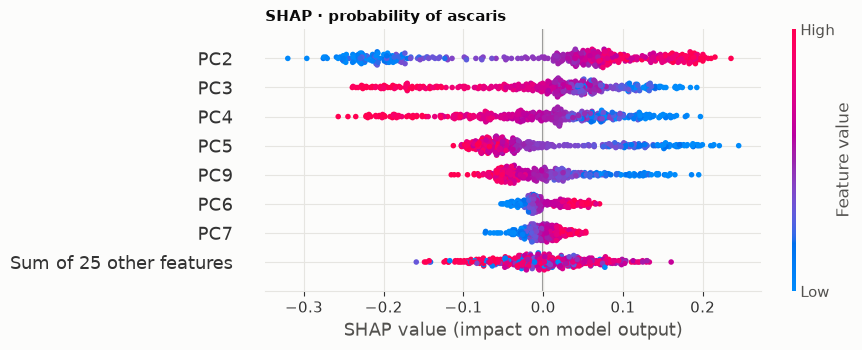

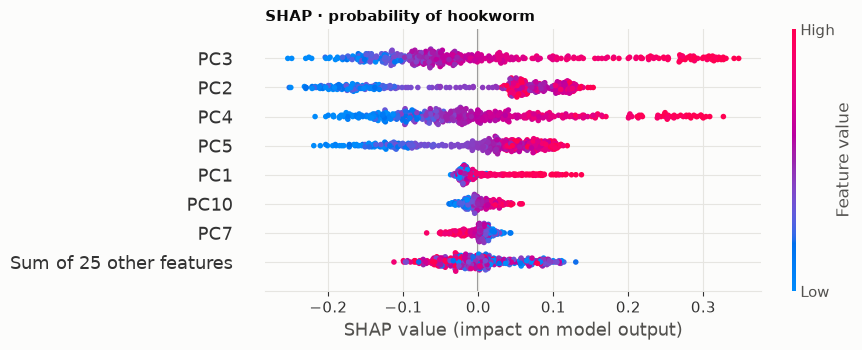

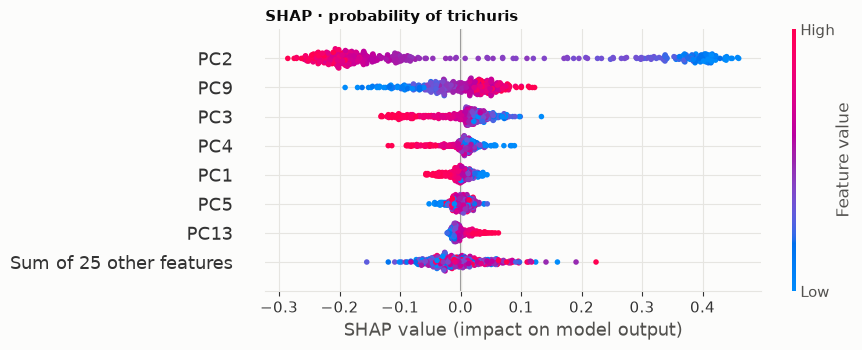

In [34]:
for index, name in enumerate(forest.named_steps["model"].classes_):
    plt.figure()
    shap.plots.beeswarm(forest_shap[:, :, index], max_display=8, show=False, plot_size=(8, 3.4))
    plt.title(f"SHAP · probability of {name}", loc="left", fontweight="bold")
    plt.show()

**¿Qué es cada componente?** Un componente del PCA es una dirección del embedding; se entiende mirando los
recortes que quedan en sus dos extremos.

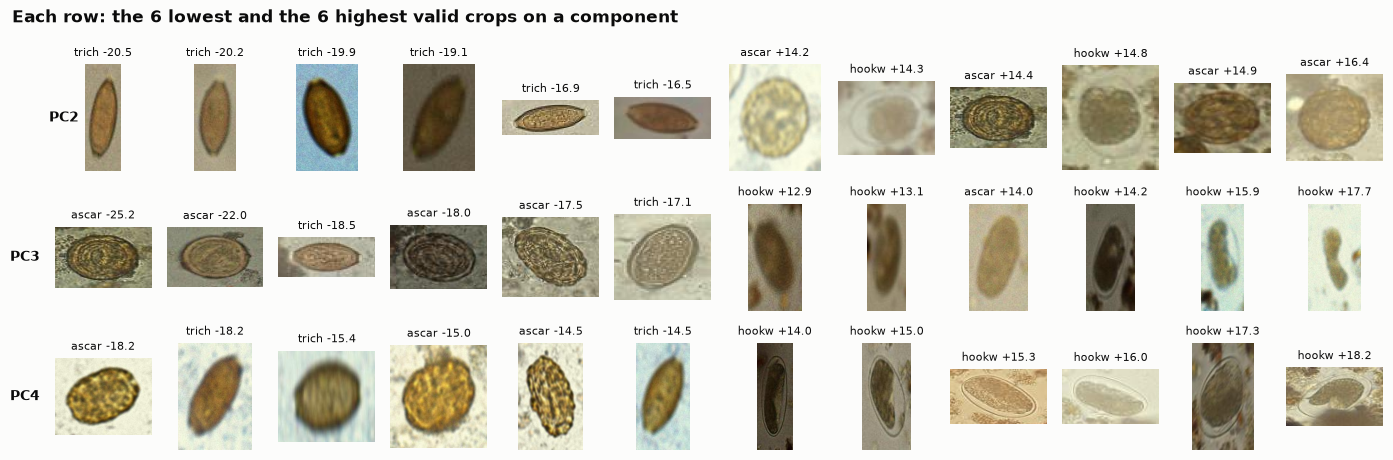

In [35]:
valid_paths = crops.crop_path[is_valid].to_numpy()
shown = list(top_components[:3])
fig, axes = plt.subplots(len(shown), 12, figsize=(14, 1.35 * len(shown) + 0.6))
for row, component in enumerate(shown):
    values = forest_features[:, component_names.index(component)]
    order = np.argsort(values)
    for col, index in enumerate(np.concatenate([order[:6], order[-6:]])):
        show_crop(axes[row, col], valid_paths[index], f"{y_valid[index][:5]} {values[index]:+.1f}")
    axes[row, 0].text(-0.15, 0.5, component, transform=axes[row, 0].transAxes, ha="right", va="center",
                      fontweight="bold")
fig.suptitle("Each row: the 6 lowest and the 6 highest valid crops on a component", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout()
plt.show()

,ascaris,hookworm,trichuris,total
box_size,0.113,0.060,0.146,0.319
abs_log_aspect,0.062,0.032,0.080,0.173
warmth,0.063,0.055,0.034,0.152
contrast,0.037,0.039,0.056,0.132
brightness,0.027,0.048,0.032,0.107
log_aspect,0.036,0.020,0.041,0.098


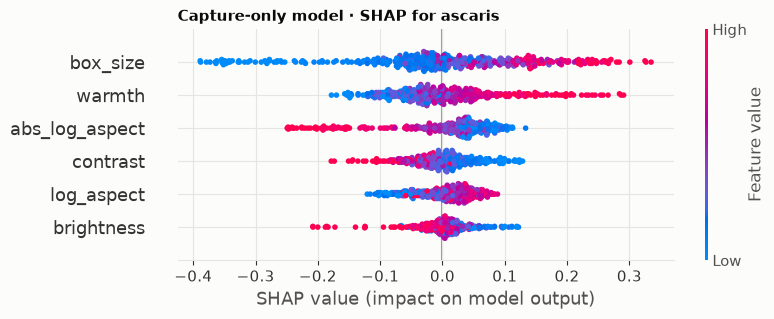

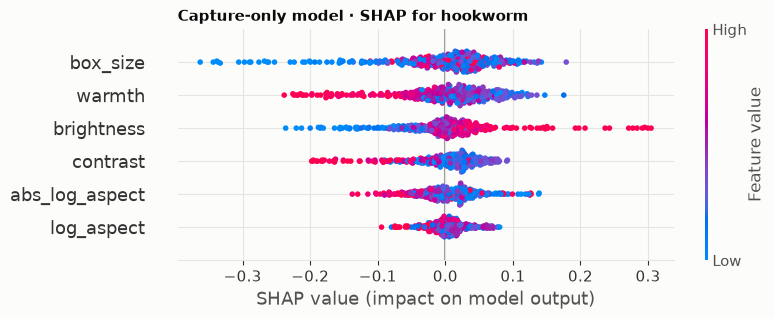

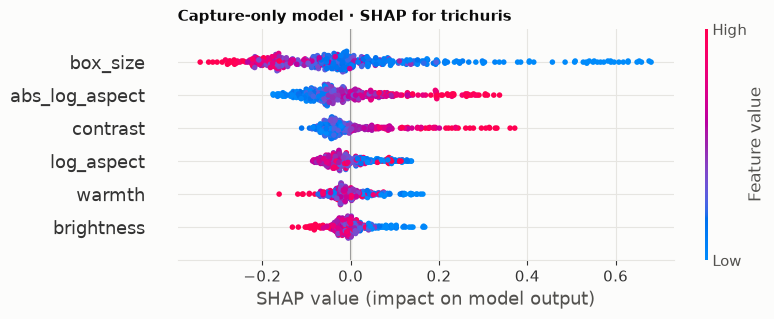

In [36]:
shortcut_explainer = shap.TreeExplainer(shortcut_model)
shortcut_shap = shortcut_explainer(capture_features[is_valid].reset_index(drop=True))
display(pd.DataFrame(np.abs(shortcut_shap.values).mean(axis=0), index=capture_features.columns,
                     columns=shortcut_model.classes_).assign(total=lambda t: t.sum(axis=1))
        .sort_values("total", ascending=False).round(4))
for index, name in enumerate(shortcut_model.classes_):
    plt.figure()
    shap.plots.beeswarm(shortcut_shap[:, :, index], show=False, plot_size=(8, 3))
    plt.title(f"Capture-only model · SHAP for {name}", loc="left", fontweight="bold")
    plt.show()

**Lectura de SHAP.**

- **Random Forest sobre el PCA.** Las direcciones que más usa son **PC2, PC3 y PC4**, y al mirar sus extremos tienen
  sentido morfológico:
  - **PC2 = forma**: alargados tipo barril (*Trichuris*, valores negativos) contra redondos (*Ascaris*, uncinaria).
    Es el componente que más pesa para *Trichuris*.
  - **PC3 = cáscara**: gruesa y con anillos concéntricos (*Ascaris*) contra delgada (uncinaria).
  - **PC4 = contenido**: granular y oscuro, con superficie mamelonada (*Ascaris*), contra una cáscara transparente
    con espacio claro alrededor de los blastómeros (uncinaria).

  Son los mismos rasgos que usa un microscopista (sección 1). El PC1, que es la dirección de mayor variación, casi
  no se usa: la variación más grande del embedding no es la especie (probablemente es la calidad de captura que
  separa el cuarto grupo de la sección 4.1).
- **Modelo de control de atajos.** Lo que más le sirve es el **tamaño de la caja**, seguido por la forma y el
  color. Confirma la lectura de la sección 6.4: el tamaño y la forma son en buena parte biología, y el color es la
  pista de captura que hay que vigilar con fotos de otras fuentes.

## 10. Despliegue e interfaz (3.8)

### 10.1 El paquete del modelo

El modelo final (`StandardScaler → PCA → SVM lineal` con probabilidades, entrenado en `train + valid`) se guarda en
`artifacts/ml/egg_classifier.joblib` con todo lo que necesita la app: las clases, los dos umbrales de rechazo,
las referencias para la similitud (embeddings de `train + valid`, normalizados), las métricas de `valid` y
`test`, y las versiones de las librerías. Es la **tarjeta del modelo** en forma de archivo. Los pesos no se suben
al repositorio (`artifacts/` está en `.gitignore`); se distribuyen por USB junto con el detector.

In [37]:
BUNDLE_PATH.parent.mkdir(parents=True, exist_ok=True)
bundle = {
    "model": final_model,
    "classes": list(final_model.classes_),
    "conf_threshold": CONF_THRESHOLD,
    "similarity_threshold": SIMILARITY_THRESHOLD,
    "reference": unit_reference.astype(np.float16),
    "embedding": "DINOv2 ViT-B/14, CLS token, crop padded to square, 224 px, ImageNet normalization",
    "detector": "artifacts/yolo/h_single_aug/weights/best.pt (YOLO11n, 1 class, conf 0.25)",
    "model_name": CHOSEN,
    "params": {k: v for k, v in chosen_params.items()},
    "metrics": {
        "valid_f1_macro": float(f1_score(y_valid, valid_pred, average="macro")),
        "test_f1_macro": float(f1_score(y_test, test_pred, average="macro")),
        "test_f1_macro_yolo_crops": float(f1_score(det_test.label[is_egg_test], det_test_species[is_egg_test],
                                                   average="macro")),
    },
    "trained_on": "Chula-ParasiteEgg-11 (Roboflow parasites-trgfz v1), team split 70/15/15 seed 42, train + valid",
    "intended_use": "Decision support for trained staff. Never a diagnosis: an expert confirms every result.",
    "versions": {"scikit-learn": sklearn.__version__, "numpy": np.__version__},
    "created": pd.Timestamp.now().isoformat(timespec="seconds"),
}
joblib.dump(bundle, BUNDLE_PATH, compress=3)
print(f"Saved {BUNDLE_PATH.relative_to(ROOT)} ({BUNDLE_PATH.stat().st_size / 1e6:.1f} MB)")
print(json.dumps({k: v for k, v in bundle.items() if k not in ("model", "reference")}, indent=2, default=str))

Saved artifacts/ml/egg_classifier.joblib (6.8 MB)
{
  "classes": [
    "ascaris",
    "hookworm",
    "trichuris"
  ],
  "conf_threshold": 0.680636539872155,
  "similarity_threshold": 0.7149401903152466,
  "embedding": "DINOv2 ViT-B/14, CLS token, crop padded to square, 224 px, ImageNet normalization",
  "detector": "artifacts/yolo/h_single_aug/weights/best.pt (YOLO11n, 1 class, conf 0.25)",
  "model_name": "Linear SVM",
  "params": {
    "model__C": 0.003,
    "pca__n_components": null
  },
  "metrics": {
    "valid_f1_macro": 0.9902575434305659,
    "test_f1_macro": 0.9975845093534623,
    "test_f1_macro_yolo_crops": 0.9975668775668775
  },
  "trained_on": "Chula-ParasiteEgg-11 (Roboflow parasites-trgfz v1), team split 70/15/15 seed 42, train + valid",
  "intended_use": "Decision support for trained staff. Never a diagnosis: an expert confirms every result.",
  "versions": {
    "scikit-learn": "1.9.0",
    "numpy": "2.5.2"
  },
  "created": "2026-11-02T23:11:07"
}


### 10.2 La app

`src/app/app.py` es una interfaz local (Gradio) que corre en la laptop **sin internet**:

```bash
python src/app/app.py              # abre http://127.0.0.1:7860
python src/app/app.py --lan        # la sirve en la red local (hotspot de la laptop) para abrirla desde el celular
```

Flujo, pensado para alguien sin formación técnica:

1. **Subir o tomar la foto** del campo del microscopio y pulsar **Analizar**.
2. La app dibuja una caja por huevo con la especie y la confianza en palabras ("muy segura", "revisar"). Los
   huevos **dudosos** salen en otro color con el aviso **"consulte a un experto"**.
3. **Sumar a la lámina**: el conteo de la foto se agrega a la lámina en curso (por especie, con los dudosos
   aparte, para que el usuario los confirme al microscopio).
4. **Cerrar la lámina**: estimación del HPG (conteo × 24, Kato-Katz de 41,7 mg) y de la intensidad según los
   umbrales de la OMS, siempre presentada como **estimación de apoyo**.

La app no guarda las fotos ni nombres: solo un registro local (`artifacts/app_logs/predictions.csv`) con la
fecha, una huella de la foto y las señales del modelo, que es la base del monitoreo de la sección 11.

Tiempo de respuesta **en CPU** (como en la laptop de campo, sin GPU), con el pipeline completo (YOLO + DINOv2 +
clasificador) sobre 20 fotos de `valid`. Se mide en un proceso aparte (`src/app/benchmark.py`), igual que corre
la app, y muestra la salida para una foto.

In [38]:
benchmark = subprocess.run([sys.executable, "src/app/benchmark.py", "--images", "data/raw/valid/images", "--n", "20"],
                           cwd=ROOT, capture_output=True, text=True, check=True)
print(benchmark.stdout)

{
  "device": "cpu",
  "photos": 20,
  "eggs_found": 20,
  "ms_per_photo_mean": 95,
  "ms_per_photo_max": 122,
  "example": {
    "photo": "Ascaris-lumbricoides_0005_jpg.rf.0f1dc4d6fb06ce4bdfbd18f42912b825.jpg",
    "eggs": [
      {
        "box": [
          251.7,
          248.7,
          363.2,
          441.4
        ],
        "det_score": 0.941,
        "species": "ascaris",
        "prob": 1.0,
        "probs": {
          "ascaris": 1.0,
          "hookworm": 0.0,
          "trichuris": 0.0
        },
        "similarity": 0.997,
        "status": "ok",
        "reason": ""
      }
    ]
  }
}



## 11. Estrategia de reajuste (3.9)

El modelo se entrenó con fotos de un laboratorio de Tailandia; en el Chocó cambiarán el microscopio, el celular,
la luz y la preparación (salina, lugol, Kato-Katz). La degradación es esperable, así que el plan es
**detectarla con datos que la app ya produce** y reentrenar con criterio.

### 11.1 Qué se monitorea (sin etiquetas, en la laptop)

La app registra para cada huevo la **confianza** y la **similitud con el entrenamiento**. Por lote de fotos
(una brigada, una semana) se calculan:

| Señal | Qué indica | Referencia |
|---|---|---|
| **Similitud mediana** con el entrenamiento | Cambio de distribución (*drift*): las fotos ya no se parecen a las de entrenamiento | La de `valid` |
| **Tasa de huevos dudosos** | El modelo duda más de lo normal | ~2 % en `valid` |
| Mezcla de especies y huevos por foto | Cambio en la población o fallas del detector | Histórico de la brigada |
| Correcciones del microscopista (cuando confirma o corrige un dudoso) | **Etiquetas reales** para medir el error | — |

La celda siguiente muestra que el monitoreo **sí detecta** un cambio de captura sin necesitar etiquetas: se usan
los lotes alterados de la sección 6.5 como si fueran brigadas con otro equipo.

In [39]:
reference_similarity = np.median(closest_similarity(perturbed_vectors["original"], unit_train))
rows = []
for name, vectors in perturbed_vectors.items():
    proba = probabilistic_model.predict_proba(vectors)
    similarity = closest_similarity(vectors, unit_train)
    doubtful = (proba.max(axis=1) < CONF_THRESHOLD) | (similarity < SIMILARITY_THRESHOLD)
    rows.append({"batch": name, "median similarity": np.median(similarity),
                 "doubtful rate": doubtful.mean(),
                 "F1 (needs labels)": robustness.loc[name, "valid F1"]})
monitor = pd.DataFrame(rows).set_index("batch")
baseline_doubtful = monitor.loc["original", "doubtful rate"]
monitor["alarm"] = np.where((monitor["median similarity"] < reference_similarity - 0.03)
                            | (monitor["doubtful rate"] > max(2 * baseline_doubtful, 0.05)), "REVIEW", "ok")
display(monitor.round(3))

,median similarity,doubtful rate,F1 (needs labels),alarm
batch,,,,
original,0.919,0.029,0.990,ok
darker (×0.6),0.915,0.027,0.993,ok
brighter (×1.4),0.901,0.070,0.983,REVIEW
low contrast (×0.6),0.914,0.034,0.990,ok
blur (radius 2),0.842,0.191,0.951,REVIEW
blur (radius 4),0.673,0.685,0.739,REVIEW
JPEG quality 15,0.817,0.254,0.921,REVIEW
low resolution (×0.35),0.846,0.145,0.961,REVIEW
warm cast (lugol-like),0.914,0.029,0.981,ok


**Resultado.** Sin usar ninguna etiqueta, el monitor marca **REVIEW** en todos los lotes donde el F1 cae más de
1 punto (desenfoque, JPEG fuerte, baja resolución) y también en el lote más claro (tasa de dudosos 7 %). Deja
pasar los cambios que no afectan al modelo (más oscuro, menos contraste, tinte cálido). La regla
(caída de similitud mediana > 0,03 o tasa de dudosos > 2× la de `valid` y > 5 %) se fijó con estos datos y debe
recalibrarse con los primeros lotes reales de campo.

### 11.2 Cuándo reentrenar

| Disparador | Criterio |
|---|---|
| **Drift** | La similitud mediana de un lote cae más de 0,03 por debajo de la de `valid`, o la tasa de dudosos supera el doble de la de `valid` (y al menos 5 %), en dos lotes seguidos |
| **Error medido** | Con los dudosos que confirma el experto y una revisión mensual de una muestra al azar de los aceptados: si el F1 macro estimado cae más de 5 puntos frente a `test`, o el recall de alguna especie baja de 0,90 |
| **Volumen** | Cada 200 huevos nuevos confirmados por un experto, aunque no haya alarma |
| **Frecuencia mínima** | Revisión trimestral de las señales aunque nada se dispare |

### 11.3 Cómo se reentrena, valida y pone en producción

1. **Recolección:** las fotos dudosas y una muestra al azar de las aceptadas se guardan en la laptop (sin datos
   del paciente) y se sincronizan cuando hay conexión (regreso a Quibdó o Medellín).
2. **Etiquetado:** un parasitólogo de la UPB confirma la especie y dibuja las cajas.
3. **Reentrenamiento:** se repite este notebook con las fotos nuevas agregadas a `train`, **agrupadas por foto y
   estratificadas por fuente** (Chula, UPB, campo), con la misma búsqueda de hiperparámetros. Si cambia mucho la
   captura, también se reentrena el detector (en Apolo III). Como DINOv2 está congelado, reentrenar el clasificador
   toma minutos en una laptop.
4. **Validación (campeón contra retador):** el modelo nuevo se compara con el actual en (a) el `test` congelado
   de Chula, (b) un `test` nuevo de fotos de campo apartado desde el inicio y nunca usado para entrenar. Se publica
   solo si **no empeora** el F1 macro ni el recall de ninguna especie en (a) y **mejora** en (b), con intervalos
   de bootstrap.
5. **Puesta en producción:** paquete versionado (`egg_classifier_vN.joblib` + detector + tarjeta del modelo con
   fecha, datos y métricas), distribuido por USB o descarga. La versión anterior se conserva para volver atrás si
   el monitoreo empeora.

## 12. Conclusiones y limitaciones

1. **El problema se resuelve bien en fotos de laboratorio.** Con embeddings DINOv2 congelados, una **SVM lineal**
   clasifica los huevos con F1 macro 0,99 en validación cruzada y en `valid`, y 0,998 en `test`. El sistema completo
   (YOLO + SVM) cuenta exactamente los huevos de casi el 97 % de las fotos de prueba, en ~90 ms por foto en CPU y sin
   internet.
2. **La selección fue sistemática y sin fuga.** Seis familias de modelos, 160 configuraciones, validación cruzada
   agrupada por foto, escalado y PCA dentro de cada pliegue, `test` tocado una sola vez. El modelo más simple fue el
   mejor: la representación preentrenada hace que una frontera lineal baste.
3. **El no supervisado explica el porqué.** Sin etiquetas, el embedding separa a *Trichuris* pero mezcla especie con
   calidad de captura (el cuarto grupo de K-Means, el ruido de DBSCAN). Las etiquetas son necesarias, y el mismo
   espacio sirve para detectar fotos raras.
4. **El modelo mira la morfología.** SHAP muestra que los componentes más usados codifican forma, cáscara y
   contenido del huevo, que son los rasgos del diagnóstico al microscopio.
5. **Riesgos identificados y medidos:** la nitidez (−4 a −25 puntos), los objetos parecidos a huevos que el rechazo no
   atrapa, y un posible atajo de color. El monitoreo de similitud y de dudosos detecta los cambios de captura sin
   etiquetas y define cuándo reentrenar.

**Siguiente paso:** las fotos externas de la UPB y de campo (con su especie confirmada) para medir la caída real
frente al criterio del proyecto (≤ 10 puntos de F1), y la clase "otro / sin parásito".

**Limitaciones.**

- **Una sola fuente de entrenamiento** (Chula, Tailandia). El desempeño en fotos de celular del Chocó está por
  medir: las fotos externas con especie confirmada están pendientes de la UPB. La prueba de robustez (6.5) es un
  sustituto parcial.
- **Fotos estiradas ~7 %** por el preprocesamiento de Roboflow (sección 3.3).
- **Sin clase "no es huevo"**: las falsas alarmas del detector se atrapan con el rechazo, no con una clase propia.
  Agregar las otras 8 especies de Chula y campos vacíos como clase "otro" es el siguiente paso.
- **Probabilidades sin calibración externa**: la confianza es una guía, no una probabilidad garantizada en campo.
- **El HPG supone Kato-Katz** (41,7 mg) y la lectura de toda la lámina; con otra preparación el factor 24 no aplica.

**Referencias.** Chula-ParasiteEgg-11 (ICIP 2022 Challenge, CC BY 4.0) · Oquab et al., 2023, *DINOv2* · Ultralytics
YOLO11 · Lundberg & Lee, 2017, *SHAP* · Pedregosa et al., 2011, *scikit-learn* · OMS: Montresor et al., 1998,
*Guidelines for the evaluation of soil-transmitted helminthiasis and schistosomiasis at community level*
(umbrales de intensidad por HPG).